# 🌐 Mini Project NLP: Machine Translation Indonesia → Inggris
## Perbandingan Arsitektur Seq2Seq Encoder–Decoder tanpa Attention vs dengan Bahdanau Attention

---

### 👥 Identitas Kelompok

> **Mata Kuliah:** Pemrosesan Bahasa Alami (NLP) — Pertemuan 10  
> **Kelompok:** **Kelompok 1A TIA**  
> **Program Studi:** S1 Teknik Informatika — Universitas Negeri Malang (UM)  
> **Dosen Pengampu:** Prof. Aji Prasetya Wibawa, S.T., M.M.T., Ph.D. & M. Zainal Arifin, S.Si., M.Kom. Ph.D.  
> **Mentor:** Agung Bella Putra Utama & Fadia Irsania Putri  

| No | NIM | Nama Mahasiswa | Peran |
| :---: | :---: | :--- | :---: |
| 1 | 240535600363 | **ASYAM SAKHI MAULANA** | **Ketua Kelompok** |
| 2 | 240535607403 | **AGUSTINUS MARIA AGUNG HERIYANTO** | Anggota |
| 3 | 240535601034 | **ALBI ADWITIYA CHANDRA** | Anggota |
| 4 | 240535604624 | **CHRISTIAN LIONEL DAUN DARMA** | Anggota |
| 5 | 240535610197 | **INDAH HARIYANTI** | Anggota |

---

### 1. Deskripsi Eksperimen
Eksperimen ini membandingkan dua model *Neural Machine Translation* (NMT) untuk menerjemahkan Bahasa Indonesia ke Bahasa Inggris pada korpus berita PANL-BPPT:

- **Model 1**: Seq2Seq Encoder–Decoder tanpa Attention. Decoder hanya menerima satu vektor ringkasan dari encoder.
- **Model 2**: Seq2Seq Encoder–Decoder dengan Bahdanau (*additive*) Attention. Pada setiap langkah decoding, decoder menghitung *context vector* dari seluruh keluaran encoder.

Kedua model memakai dataset, preprocessing, pembagian data, vocabulary, ukuran arsitektur dasar, hyperparameter training, dan metode decoding yang identik, sehingga perbedaan hasil dapat ditelusuri pada ada tidaknya mekanisme Attention.

Aspek yang dibandingkan: kualitas terjemahan, kemampuan menangani kalimat panjang, skor BLEU, waktu training, contoh prediksi, visualisasi Attention/alignment, dan analisis error.

Alur pipeline: Dataset → Tokenisasi → Padding → Encoder → Decoder → Attention → Decoding → Evaluasi.


## 2. Setup dan Konfigurasi
Seed acak ditetapkan (`SEED = 42`) pada Python, NumPy, dan PyTorch agar pembagian data, inisialisasi model, dan urutan batch dapat direproduksi.

Seed acak ditetapkan pada Python, NumPy, dan PyTorch untuk mengendalikan sumber keacakan selama eksperimen. Perangkat komputasi yang digunakan dicatat sebagai bagian dari pelaporan waktu pelatihan agar perbandingan biaya komputasi kedua model memiliki konteks yang jelas.

In [ ]:
import os, re, io, json, time, math, random, zipfile, collections, difflib, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)
if device.type == "cpu":
    print("Catatan: GPU tidak tersedia; training berjalan pada CPU dan memerlukan waktu jauh lebih lama.")

M1, M2 = "Model 1 (tanpa attention)", "Model 2 (+ attention)"

PyTorch: 2.11.0+cu130 | Device: cuda


## 3. Dataset dan Karakteristik Data
**Sumber data.** Dataset yang digunakan adalah korpus paralel Indonesia–Inggris **PANL-BPPT**, hasil proyek *PAN Localization* (BPPT), berisi kalimat berita pada empat topik: ekonomi, internasional, sains/teknologi, dan olahraga.
- Halaman dataset: https://huggingface.co/datasets/cahya/id_panl_bppt
- Data mentah: https://github.com/cahya-wirawan/indonesian-language-models/raw/master/data/BPPTIndToEngCorpusHalfM.zip

**Alasan pemilihan.** Kalimat berita memiliki rentang panjang yang lebar, sehingga perbandingan kemampuan menangani kalimat pendek, sedang, dan panjang dapat dilakukan. Distribusi panjang aktual disajikan pada bagian 4.

**Penyaringan korpus.** Korpus mentah diproses menjadi berkas `dataset_id_en_panl.csv` (kolom `id` untuk sumber dan `en` untuk target) melalui tahapan berikut:
1. Kalimat Indonesia dan Inggris dipasangkan baris demi baris untuk setiap topik.
2. Pasangan dengan panjang di luar 3–40 token (setelah preprocessing dasar) dikeluarkan agar biaya komputasi terkendali dan kalimat yang terlalu pendek atau terlalu panjang tidak mendominasi.
3. Pasangan duplikat dikeluarkan.
4. Pasangan dengan rasio panjang (Inggris+1)/(Indonesia+1) di luar 0,5–2,0 dikeluarkan. Ini merupakan **heuristik** untuk menyaring kandidat pasangan yang tidak sejajar; heuristik ini tidak menjamin bahwa pasangan yang tersisa sepadan secara makna.

Pasangan yang dikeluarkan oleh langkah 4 disimpan pada `audit_dibuang_rasio.csv` sebagai dokumentasi.

In [ ]:
DATA_PATH = "dataset_id_en_panl.csv"
PANL_URL = "https://github.com/cahya-wirawan/indonesian-language-models/raw/master/data/BPPTIndToEngCorpusHalfM.zip"
MIN_TOK, MAX_TOK = 3, 40          # batas panjang kalimat (jumlah token setelah preprocessing dasar)
RATIO_LO, RATIO_HI = 0.5, 2.0     # batas rasio panjang (Inggris+1)/(Indonesia+1)

def _ntok(s):
    s = re.sub(r"([.,!?])", r" \1 ", str(s).lower().strip())
    return len(re.sub(r"\s+", " ", s).strip().split())

def _panl_pairs(verbose=True):
    """Unduh PANL-BPPT, lalu kembalikan (pasangan_dipakai, pasangan_dibuang_filter_rasio)."""
    raw = urllib.request.urlopen(PANL_URL, timeout=180).read()
    zf = zipfile.ZipFile(io.BytesIO(raw))
    names = zf.namelist()
    rows = []
    for topic in ["ECO", "INT", "SCI", "SPO"]:
        f_id = [n for n in names if f"PANL-BPPT-{topic}-ID-" in n and n.endswith(".txt")][0]
        f_en = [n for n in names if f"PANL-BPPT-{topic}-EN-" in n and n.endswith(".txt")][0]
        a = zf.read(f_id).decode("utf-8").split("\n")
        b = zf.read(f_en).decode("utf-8").split("\n")
        if a and a[-1] == "": a = a[:-1]
        if b and b[-1] == "": b = b[:-1]
        assert len(a) == len(b), f"jumlah baris tidak sama untuk topik {topic}: {len(a)} vs {len(b)}"
        rows += [(x.strip(), y.strip()) for x, y in zip(a, b)]
    d = pd.DataFrame(rows, columns=["id", "en"])
    if verbose: print("Pasangan mentah             :", len(d))
    li, le = d["id"].map(_ntok), d["en"].map(_ntok)
    d = d[li.between(MIN_TOK, MAX_TOK) & le.between(MIN_TOK, MAX_TOK)]
    if verbose: print(f"Setelah filter {MIN_TOK}-{MAX_TOK} token     :", len(d))
    d = d.drop_duplicates(["id", "en"]).reset_index(drop=True)
    if verbose: print("Setelah buang duplikat      :", len(d))
    li, le = d["id"].map(_ntok), d["en"].map(_ntok)
    r = (le + 1) / (li + 1)
    ok = (r >= RATIO_LO) & (r <= RATIO_HI)
    kept, removed = d[ok].reset_index(drop=True), d[~ok].reset_index(drop=True)
    if verbose: print("Setelah filter rasio panjang:", len(kept))
    return kept, removed

def build_panl_csv(path):
    kept, removed = _panl_pairs()
    removed.to_csv("audit_dibuang_rasio.csv", index=False)      # bahan audit pasangan yang dibuang (bagian 1b)
    kept.to_csv(path, index=False)

if not os.path.exists(DATA_PATH):
    try:
        build_panl_csv(DATA_PATH)
    except Exception as e:
        raise RuntimeError(f"Dataset {DATA_PATH} tidak tersedia dan pengunduhan korpus PANL-BPPT gagal: {e!r}")

df = pd.read_csv(DATA_PATH).dropna().reset_index(drop=True)
print("File dataset  :", os.path.abspath(DATA_PATH))
print("Jumlah pasangan kalimat:", len(df))
# pemeriksaan: korpus PANL-BPPT hasil penyaringan berukuran lebih dari 15.000 pasangan
assert len(df) > 15000, f"Dataset hanya berisi {len(df)} pasangan; korpus PANL-BPPT yang diharapkan berukuran lebih dari 15.000 pasangan."
df.head(8)

Pasangan mentah             : 24024
Setelah filter 3-40 token     : 21655
Setelah buang duplikat      : 21646
Setelah filter rasio panjang: 21529
File dataset  : /content/dataset_id_en_panl.csv
Jumlah pasangan kalimat: 21529


,id,en
0,Kita melihat faktor inflasi dari makanan akan ...,"Sri Mulayani showed other factors, among other..."
1,Demikian pula dengan harga minyak.,This also happened to fuel oil prices.
2,"Kondisi APBN 2007 pada dua pekan awal, secara ...",The 2007 state budget is so far in a good cond...
3,"Menurut data Depkeu, net buy obligasi negara a...",The ministry?s data also showed non resident i...
4,Sedangkan untuk net buy saham oleh investor as...,Meanwhile non resindent investors? net buying ...
5,"Kalau ditanya ini baik atau tidak, saya kataka...","If you ask if it is right or not, I can say it..."
6,"Di sektor riil, pemerintah telah mengeluarkan ...","In the real sector, the government has issued ..."
7,"Pada hari ini, Presiden baru mengeluarkan Perp...","Today, the President has issued a presidential..."


### 3.1 Pemeriksaan Awal Konsistensi Dataset

Bagian ini menyajikan pemeriksaan diagnostik awal terhadap pasangan kalimat dalam korpus. Pemeriksaan meliputi pasangan yang dikeluarkan berdasarkan filter rasio panjang, perbedaan angka antara kalimat sumber dan target, serta kemunculan tanda tanya di antara huruf yang mengindikasikan kemungkinan artefak encoding.

Indikator tersebut digunakan untuk mengidentifikasi potensi masalah pada data. Perbedaan angka maupun kemunculan karakter tertentu tidak secara otomatis membuktikan bahwa pasangan terjemahan tidak sejajar, sehingga hasil pemeriksaan tetap diinterpretasikan sebagai indikasi kualitas data, bukan label kesalahan yang definitif.

In [ ]:
pd.set_option("display.max_colwidth", 200)
print("Contoh 8 pasangan acak dari dataset (random_state=2026):")
display(df.sample(8, random_state=2026)[["id", "en"]])

# (a) pasangan yang dikeluarkan filter rasio panjang
dibuang = None
if os.path.exists("audit_dibuang_rasio.csv"):
    dibuang = pd.read_csv("audit_dibuang_rasio.csv")
else:
    try:                                   # dataset sudah tersedia sebelumnya: susun ulang daftar pasangan yang dikeluarkan
        dibuang = _panl_pairs(verbose=False)[1]
        dibuang.to_csv("audit_dibuang_rasio.csv", index=False)
    except Exception as e:
        print("Daftar pasangan yang dikeluarkan filter rasio tidak dapat disusun ulang:", repr(e))
if dibuang is not None:
    print(f"\n(a) Filter rasio panjang [{RATIO_LO}, {RATIO_HI}] mengeluarkan {len(dibuang)} pasangan "
          f"({100 * len(dibuang) / (len(dibuang) + len(df)):.2f}% dari pasangan yang lolos tahap penyaringan sebelumnya). Contoh 8 pasangan:")
    display(dibuang.sample(min(8, len(dibuang)), random_state=5)[["id", "en"]])

# (b) kesesuaian angka antar-kalimat
def _angka(s):
    return set(re.findall(r"\d+", str(s).replace(".", "").replace(",", "")))
na, nb_ = df["id"].map(_angka), df["en"].map(_angka)
punya = (na.map(len) > 0) & (nb_.map(len) > 0)
beda = punya & pd.Series([len(x & y) == 0 for x, y in zip(na, nb_)], index=df.index)
print(f"\n(b) Dari {int(punya.sum())} pasangan yang memuat angka pada kedua sisi, {int(beda.sum())} "
      f"({100 * beda.sum() / max(punya.sum(), 1):.1f}%) tidak memiliki angka yang sama sama sekali; pasangan ini berpotensi tidak sejajar. Contoh 5 pasangan:")
display(df[beda][["id", "en"]].head(5))

# (c) artefak tanda '?' di antara huruf
art = df["en"].str.contains(r"[A-Za-z]\?[A-Za-z]", regex=True) | df["id"].str.contains(r"[A-Za-z]\?[A-Za-z]", regex=True)
print(f"\n(c) Pasangan dengan tanda '?' di antara huruf (mis. apostrof yang berubah menjadi '?'): {int(art.sum())} dari {len(df)} ({100 * art.mean():.2f}%).")

Contoh 8 pasangan acak dari dataset (random_state=2026):


,id,en
15807,ROM biasanya digunakan untuk menyimpan perintah-perintah awal untuk membuka komputer.,ROM is typically used to store the computer's initial start up instructions.
17116,"Mungkin terlihat aneh bahwa fosil dari suatu daerah kecil, betapapun menariknya, ternyata menjadi pusat perdebatan sengit tentang permasalahan seluas itu dalam biologi evolusi.","It might seem odd that fossils from one small locality, no matter how exciting, should lie at the center of a fierce debate about such broad issues in evolutionary biology."
304,"Pelaku pasar, lanjut dia masih menunggu keluarnya data indikator ekonomi AS yang akan menunjukkan pertumbuhan ekonomi AS membaik atau makin melemah","Market players, she said, were still waiting for the issuance of data on US economic indicators which would show whether the US economy will strengthen or weaken."
16552,Mathew Nagle adalah salah seorang yang membantu penelitian ini dengan menjadi objek uji coba.,Mthew Nagle is s scientist helping the study to become the object of the experiment.
18958,Posisi Benitez tampaknya semakin tidak bisa dipertahankan setelah pemilik Liverpool asal Amerika mengakui telah melakukan pembicaraan dengan Jurgen Klinsmann mengenai pekerjaan sebagai manajer akh...,Benitez's position looks increasingly untenable after Liverpool's American owners admitted they held talks with Jurgen Klinsmann over the manager's job late last year.
10368,"Jika Perdana Menteri (Jepang, Shinzo) Abe berkunjung ke China pada Oktober lalu merupakan lawatan untuk memecahkan es, maka saya ingin kunjungan saya ini akan menjadi kunjungan mencairkan es, kata...","If (Japanese) Prime Minister (Shinzo) Abe's visit to China in October was a trip to break the ice, I want my visit to be an ice-melting visit, he said."
40,"Sementara itu Direktur Utama PT Mirantha Nuansa Ayu, Henry Sulysto, mengatakan, kerjasama dengan perusahaan penyewaan pesawat sangat diperlukan karena tidak mungkin perseroan menyediakan pesawat s...","Meanwhile, President Director of PT Mirantha Nuansa Ayu travel agency Henry Sulysto said that NTT, NTB and Labuhan Bajo were potential tourist destinations."
12936,Kesemua keadaan ini harus dimonitor dan dijaga agar kinerja agensia biologis tetap optimum.,These all conditions must be monitored to make optimum performance of the biological agent.



(a) Filter rasio panjang [0.5, 2.0] mengeluarkan 117 pasangan (0.54% dari pasangan yang lolos tahap penyaringan sebelumnya). Contoh 8 pasangan:


,id,en
37,"Tingkat SD menyumbang 0,03 persen, SMP 0,03, SMA 0,07 persen, dan tingkat universitas menyumbang 0,03 persen sehingga secara kumulatif sektor pendidikan menyumbang 0,18 persen, katanya.","So far, Pertamina gasoline stations are the only premium gasoline and diesel oil retailers, he said."
46,Apa ini laporan keuangan?,What a financial report! What happened with the finance ministry.
28,"Lebih jauh ia memaparkan bahwa banyak negara-negara di Asia, dan juga Amerika Serikat, bahkan Eropa yang menawarkan peluang investasi ke Jepang, sehingga memperlihatkan terjadinya suatu peta persa...",The entourage of the Japanese prime minister will include also 51 top journalists.
10,"Prospek stabil diberikan atas peringkat-peringkat tersebut, katanya.","The ratings reflected the bank's sound assets and strong capitalization, Pefindo analysts Yans Simbolon and Hendro Utomo said in a statement."
116,Benzema dengan terus terang mengatakan tentang prioritas klubnya.,"Benzema, though, was frank about what remained the top priority of the club, that once again failed to deliver in the Champions League this term."
94,"Striker itu, yang berusia 25 tahun Senin lalu, menampik anggapan bahwa ia sakit hati dengan pemain yang mencelakainya itu.",These things can happen in football.
23,"Saya pandang perlu untuk mengakhiri format forum CGI tahun 2007 ini CGI saya nyatakan tidak perlu ada lagi, kata Presiden, saat dicegat wartawan, di halaman kompleks Istana Kepresiden Jakarta, Rabu.",I think it is necessary to terminate the CGI forum this year.
63,Delegasi dari lebih 100 negara dalam panel cuaca PBB terlibat pembicaraan sepanjang malam di Brussels.,"Delegates from more than 100 nations in the U.N. climate panel were locked in overnight talks in Brussels, seeking to overcome differences about a 21-page summary for policymakers to allow planned..."



(b) Dari 6266 pasangan yang memuat angka pada kedua sisi, 92 (1.5%) tidak memiliki angka yang sama sama sekali; pasangan ini berpotensi tidak sejajar. Contoh 5 pasangan:


,id,en
44,Nilai kontrak berdasarkan jam terbang pesawat atau paling tidak sebulan sebesar 160 ribu dolar AS per pesawat.,"The value of the contract is based on flight hours or at least US$160,000 monthly for each plane."
225,Ka'ban menyebutkan surat keputusan bersama SKB pembentukan BUPPH diharapkan sudah dapat diselesaikan paling lambat 2 Februari 2007 sehingga pada pertengahan Februrari 2007 diharapkan sudah dapat m...,Ka'ban said the drafting of a joint ministerial decree on the BUPPH's establishment was expected to be completed on February 1 at the latest and issued in mid-February.
393,"Penerimaan pajak sudah mencapai 76,8 persen dari target, sedangkan penerimaan negara bukan pajak PNBP mencapai 73,5 persen dari target, kata Menkeu.","The state receipts and expenditures respectively represented 75.5 percent and 67.3 percent of the target set in the revised 2007 state budget, she said."
412,"Apalagi hubungan kerjasama ini telah terjalin sejak 1972 dengan menjadi nasabah giro dan menjadi debitur sejak tahun 1994, ucapnya.","Meanwhile, Arifin said until 2009 Petrokimia would build nine projects, including a 25-MW coal-fired power plant."
820,Melalui kesepakatan tersebut Jepang dan Thailand akan menghapus tarif lebih dari 90 persen dalam perdagangan dalam sepuluh tahun dan Bangkok diminta untuk lebih transparan dan memberikan perlindun...,"Through the agreement, Japan and Thailand would scrap tariffs by more than 50 percent in their trade within ten years' time and Bangkok was expected to be more transparent and provide legal protec..."



(c) Pasangan dengan tanda '?' di antara huruf (mis. apostrof yang berubah menjadi '?'): 203 dari 21529 (0.94%).


## 4. Preprocessing dan Penyaringan Data
Preprocessing dasar diterapkan secara identik pada kedua model agar perbandingan performa dilakukan dalam kondisi yang setara: teks diubah menjadi huruf kecil, tanda baca `. , ! ?` dipisahkan dari kata, dan spasi berlebih dirapikan. Tanda baca lain, angka, dan nama diri tidak diproses khusus sehingga muncul sebagai token apa adanya.

In [ ]:
def clean(s):
    s = str(s).lower().strip()
    s = re.sub(r"([.,!?])", r" \1 ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

df["id_clean"] = df["id"].apply(clean)
df["en_clean"] = df["en"].apply(clean)
df[["id_clean", "en_clean"]].head(5)

,id_clean,en_clean
0,"kita melihat faktor inflasi dari makanan akan segera hilang yang terkonfirmasi dari harga beras di semua propinsi , katanya .","sri mulayani showed other factors , among others , the rupiah currency tended to strengthen , with a positive impact on the inflation ."
1,demikian pula dengan harga minyak .,this also happened to fuel oil prices .
2,"kondisi apbn 2007 pada dua pekan awal , secara umum baik dan pemerintah akan terus menjalankan kebijakan yang sound tepat , red sehingga tercipta konsistensi kebijakan yang memberikan keyakinan ke...",the 2007 state budget is so far in a good condition and the government would continue implementing sound policies to create consistency which encouraged investors .
3,"menurut data depkeu , net buy obligasi negara atau sun oleh investor asing non residence pada saat ini mencapai rp20 , 3 triliun dari posisi awal 2006 rp4 , 2 triliun .",the ministry ? s data also showed non resident investors ? net buying of state bonds had reached rp20 . 3 trillion from rp 4 . 2 trillion in early 2006 .
4,"sedangkan untuk net buy saham oleh investor asing non residence mencapai rp17 , 3 triliun dari posisi awal tahun rp2 , 1 triliun .",meanwhile non resindent investors ? net buying of shares had reached rp17 . 3 trillion from rp2 . 1 trillion in early 2006 .


### 4.1 Statistik Panjang Kalimat dan Kelompok Panjang
Kelompok panjang ditentukan dari jumlah token kalimat sumber (Indonesia) setelah preprocessing, termasuk token tanda baca: **pendek** ≤ 12 token, **sedang** 13–24 token, dan **panjang** ≥ 25 token. Kelompok ini digunakan untuk membandingkan kemampuan kedua model pada kalimat dengan panjang berbeda.

        len_id   len_en
count  21529.0  21529.0
mean      21.5     22.8
std        8.3      8.5
min        3.0      3.0
10%       11.0     12.0
50%       21.0     23.0
90%       33.0     35.0
max       40.0     40.0

                jumlah  persen
bucket                        
pendek (<=12)     3423    15.9
sedang (13-24)   10276    47.7
panjang (>=25)    7830    36.4


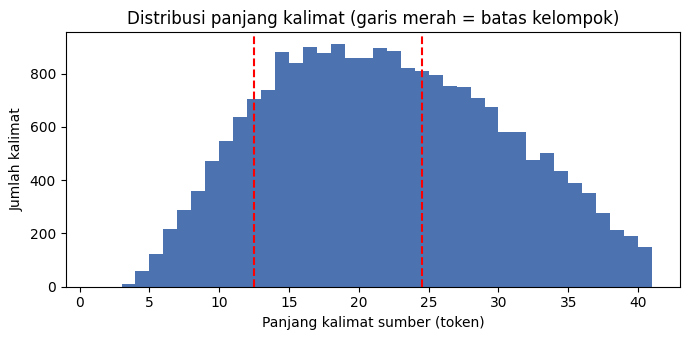

In [ ]:
BUCKETS = ["pendek (<=12)", "sedang (13-24)", "panjang (>=25)"]
def bucket(n):
    return BUCKETS[0] if n <= 12 else (BUCKETS[1] if n <= 24 else BUCKETS[2])

df["len_id"] = df["id_clean"].str.split().str.len()
df["len_en"] = df["en_clean"].str.split().str.len()
df["bucket"] = df["len_id"].apply(bucket)

print(df[["len_id", "len_en"]].describe(percentiles=[.1, .5, .9]).round(1))
print()
print(df["bucket"].value_counts().reindex(BUCKETS).to_frame("jumlah").assign(persen=lambda d: (100 * d["jumlah"] / len(df)).round(1)))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df["len_id"], bins=range(1, 42), color="#4c72b0")
for x in (12.5, 24.5):
    ax.axvline(x, color="red", ls="--")
ax.set_xlabel("Panjang kalimat sumber (token)"); ax.set_ylabel("Jumlah kalimat")
ax.set_title("Distribusi panjang kalimat (garis merah = batas kelompok)")
plt.tight_layout(); plt.savefig("fig_distribusi_panjang.png", dpi=150); plt.show()

## 5. Pembagian Dataset
Dataset dibagi menjadi 80% data latih, 10% data validasi, dan 10% data uji dengan `SEED = 42`.

Beberapa kalimat muncul lebih dari satu kali di dalam korpus (misalnya satu kalimat Indonesia memiliki dua terjemahan Inggris, atau sebaliknya). Pada pembagian acak biasa, kalimat yang sama dapat masuk ke data latih dan data uji sekaligus sehingga skor uji menjadi terlalu optimistis. Oleh karena itu digunakan **pembagian berkelompok (*grouped split*)**: pasangan yang berbagi kalimat Indonesia **atau** kalimat Inggris yang sama digabung ke dalam satu kelompok, dan setiap kelompok hanya ditempatkan pada satu bagian. Pembagian yang sama dipakai oleh kedua model.

In [ ]:
def group_ids(src, trg):
    parent = {}
    def find(x):
        while parent.setdefault(x, x) != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for s, t in zip(src, trg):
        rs, rt = find("s:" + s), find("t:" + t)
        if rs != rt:
            parent[rs] = rt
    return [find("s:" + s) for s in src]

df["grup"] = group_ids(df["id_clean"], df["en_clean"])
rng = np.random.RandomState(SEED)
uniq = pd.unique(df["grup"])
order = rng.permutation(len(uniq))
size = df.groupby("grup").size()
target_train, target_val = int(0.8 * len(df)), int(0.1 * len(df))
part, count, split_of = 0, 0, {}
for g in uniq[order]:
    if part == 0 and count >= target_train:
        part, count = 1, 0
    elif part == 1 and count >= target_val:
        part, count = 2, 0
    split_of[g] = part
    count += int(size[g])
df["split"] = df["grup"].map(split_of)

def take(p):
    ix = np.where(df["split"].values == p)[0]
    rng.shuffle(ix)
    return df.iloc[ix].reset_index(drop=True)
train_df, val_df, test_df = take(0), take(1), take(2)
test_df["len"] = test_df["len_id"]          # dipakai cell evaluasi / visualisasi
print("train / val / test :", len(train_df), len(val_df), len(test_df))

def n_bocor(col):
    return int((df.groupby(col)["split"].nunique() > 1).sum())
print("Kalimat Indonesia yang muncul di >1 bagian (grouped split):", n_bocor("id_clean"), "| kalimat Inggris:", n_bocor("en_clean"))
rp = np.random.RandomState(SEED).permutation(len(df)); tmp = np.zeros(len(df), int)
tmp[rp[int(0.8 * len(df)):int(0.9 * len(df))]] = 1; tmp[rp[int(0.9 * len(df)):]] = 2
df["_rand"] = tmp
print("Pembanding, random split biasa      :", n_bocor_r := int((df.groupby("id_clean")["_rand"].nunique() > 1).sum()),
      "kalimat Indonesia dan", int((df.groupby("en_clean")["_rand"].nunique() > 1).sum()), "kalimat Inggris bocor antar bagian.")
df = df.drop(columns=["_rand"])
assert n_bocor("id_clean") == 0 and n_bocor("en_clean") == 0
print()
print(pd.DataFrame({n: d["bucket"].value_counts().reindex(BUCKETS)
                    for n, d in [("train", train_df), ("val", val_df), ("test", test_df)]}))

train / val / test : 17223 2152 2154
Kalimat Indonesia yang muncul di >1 bagian (grouped split): 0 | kalimat Inggris: 0
Pembanding, random split biasa      : 11 kalimat Indonesia dan 12 kalimat Inggris bocor antar bagian.

                train   val  test
bucket                           
pendek (<=12)    2711   360   352
sedang (13-24)   8262  1028   986
panjang (>=25)   6250   764   816


## 6. Tokenisasi dan Vocabulary
Tokenisasi dilakukan pada tingkat kata. Vocabulary dibangun **hanya dari data latih** untuk mencegah kebocoran informasi dari data validasi dan uji, dengan token khusus `<pad>`, `<sos>`, `<eos>`, dan `<unk>`.

Pada teks berita, banyak kata hanya muncul satu kali (nama, angka, istilah teknis). Kata dengan frekuensi pada data latih di bawah `MIN_FREQ` tidak dimasukkan ke vocabulary dan diganti `<unk>`. Pengaturan ini menjaga ukuran lapisan keluaran decoder tetap terkendali dan berlaku sama untuk kedua model; konsekuensinya, kata langka tidak dapat diterjemahkan secara eksplisit.

In [ ]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3
MIN_FREQ = 2

class Vocab:
    def __init__(self, sentences, min_freq=1):
        self.itos = ["<pad>", "<sos>", "<eos>", "<unk>"]
        cnt = collections.Counter(w for s in sentences for w in s.split())
        self.itos += [w for w, c in cnt.most_common() if c >= min_freq]
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def encode(self, s):
        return [self.stoi.get(w, UNK) for w in s.split()]
    def __len__(self):
        return len(self.itos)

src_vocab = Vocab(train_df["id_clean"], MIN_FREQ)
trg_vocab = Vocab(train_df["en_clean"], MIN_FREQ)
print("Vocab Indonesia:", len(src_vocab), "| Vocab Inggris:", len(trg_vocab))

def oov_rate(vocab, sentences):
    toks = [w for s in sentences for w in s.split()]
    return sum(w not in vocab.stoi for w in toks) / len(toks)
print(f"Persentase token <unk> di test: sumber {100*oov_rate(src_vocab, test_df['id_clean']):.1f}% | target {100*oov_rate(trg_vocab, test_df['en_clean']):.1f}%")

contoh = train_df.loc[0, "id_clean"]
print(contoh)
print(src_vocab.encode(contoh))

def vocab_stats(vocab, col, nama):
    cnt = collections.Counter(w for s in train_df[col] for w in s.split())
    total = sum(cnt.values())
    covered = sum(c for w, c in cnt.items() if w in vocab.stoi)
    return {"bahasa": nama, "token unik di data latih": len(cnt), "ukuran vocabulary": len(vocab),
            "kata yang muncul 1x (data latih)": sum(1 for c in cnt.values() if c == 1),
            "cakupan token data latih (%)": round(100 * covered / total, 2),
            "token <unk> di data uji (%)": round(100 * oov_rate(vocab, test_df[col]), 2)}
display(pd.DataFrame([vocab_stats(src_vocab, "id_clean", "Indonesia (sumber)"), vocab_stats(trg_vocab, "en_clean", "Inggris (target)")]).set_index("bahasa"))

Vocab Indonesia: 13036 | Vocab Inggris: 13936
Persentase token <unk> di test: sumber 5.2% | target 5.1%
menurut dia , masuknya dolar as ke pasar domestik memberikan suntikan terhadap rupiah sehingga menguat hingga mencapai rp9 . 200 per dolar as .
[99, 83, 4, 1925, 56, 24, 22, 107, 976, 201, 3, 76, 111, 80, 605, 108, 73, 242, 5, 838, 103, 56, 24, 5]


,token unik di data latih,ukuran vocabulary,kata yang muncul 1x (data latih),cakupan token data latih (%),token <unk> di data uji (%)
bahasa,,,,,
Indonesia (sumber),24813,13036,11781,96.81,5.22
Inggris (target),26220,13936,12288,96.87,5.13


## 7. Padding dan DataLoader
Kalimat sumber diberi `<eos>` di akhir, sedangkan kalimat target diberi `<sos>` di awal dan `<eos>` di akhir. Dalam satu batch, kalimat diselaraskan panjangnya dengan `<pad>` menggunakan `pad_sequence`. Posisi `<pad>` diabaikan pada perhitungan loss (`ignore_index`) dan pada bobot Attention (mask).

In [ ]:
class MTDataset(Dataset):
    def __init__(self, data):
        self.src = [src_vocab.encode(s) + [EOS] for s in data["id_clean"]]
        self.trg = [[SOS] + trg_vocab.encode(s) + [EOS] for s in data["en_clean"]]
    def __len__(self):
        return len(self.src)
    def __getitem__(self, i):
        return self.src[i], self.trg[i]

def collate(batch):
    src = [torch.tensor(b[0]) for b in batch]
    trg = [torch.tensor(b[1]) for b in batch]
    lens = torch.tensor([len(s) for s in src])
    src = pad_sequence(src, batch_first=True, padding_value=PAD)
    trg = pad_sequence(trg, batch_first=True, padding_value=PAD)
    return src, lens, trg

BATCH = 64
train_gen = torch.Generator()   # di-reset sebelum tiap training supaya urutan batch kedua model identik
train_loader = DataLoader(MTDataset(train_df), batch_size=BATCH, shuffle=True,  collate_fn=collate, generator=train_gen)
val_loader   = DataLoader(MTDataset(val_df),   batch_size=128,   shuffle=False, collate_fn=collate)
test_loader  = DataLoader(MTDataset(test_df),  batch_size=128,   shuffle=False, collate_fn=collate)

s, l, t = next(iter(train_loader))
print("Batch src:", s.shape, "| trg:", t.shape)
print("Contoh src (dengan padding):", s[0].tolist())
print("Contoh trg (dengan padding):", t[0].tolist())

# statistik padding pada seluruh batch data latih
pad_s = tot_s = pad_t = tot_t = 0
for s_, l_, t_ in train_loader:
    pad_s += int((s_ == PAD).sum()); tot_s += s_.numel()
    pad_t += int((t_ == PAD).sum()); tot_t += t_.numel()
print(f"Proporsi posisi <pad> pada batch data latih: sumber {100 * pad_s / tot_s:.1f}% | target {100 * pad_t / tot_t:.1f}%")

Batch src: torch.Size([64, 38]) | trg: torch.Size([64, 42])
Contoh src (dengan padding): [474, 9, 828, 6, 318, 1237, 119, 3338, 1912, 6018, 6, 258, 29, 1062, 4828, 18, 4, 287, 541, 6, 3331, 458, 3, 279, 887, 117, 1567, 94, 733, 25, 4, 20, 285, 18, 5, 2, 0, 0]
Contoh trg (dengan padding): [1, 329, 13, 3, 1695, 7, 2676, 6395, 7812, 132, 9, 4, 5135, 642, 6, 336, 721, 63, 9, 13149, 3, 602, 4, 596, 7, 11, 1359, 247, 19, 827, 38, 6, 4, 326, 12, 5, 2, 0, 0, 0, 0, 0]
Proporsi posisi <pad> pada batch data latih: sumber 43.4% | target 39.7%


## 8. Arsitektur Seq2Seq tanpa Attention (Model 1)
**Encoder** (identik pada kedua model): lapisan *embedding* diikuti GRU dua arah (*bidirectional*). Keadaan tersembunyi akhir kedua arah digabung dan diproyeksikan (`tanh`) menjadi keadaan awal decoder.

**Decoder Model 1**: GRU satu arah yang menerima embedding kata sebelumnya dan keadaan tersembunyi sebelumnya, lalu memprediksi kata berikutnya melalui lapisan linear. Seluruh informasi kalimat sumber hanya dibawa oleh satu vektor ringkasan dari encoder, sehingga representasi ini menjadi *bottleneck* informasi, terutama untuk kalimat panjang.

Ukuran arsitektur dasar: dimensi embedding 64, dimensi tersembunyi GRU 128, dan dimensi ruang Attention 64 (dipakai pada Model 2). Ukuran ini sama untuk kedua model.

In [ ]:
EMB, HID, ATT = 64, 128, 64

class Encoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.rnn = nn.GRU(EMB, HID, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(HID * 2, HID)
    def forward(self, src, lens):
        e = self.emb(src)
        packed = nn.utils.rnn.pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        h = torch.tanh(self.fc(torch.cat([h[0], h[1]], dim=1)))   # [B, HID]
        return out, h                                              # out: [B, S, 2*HID]

class DecoderNoAttn(nn.Module):
    """Model 1: decoder hanya tahu hidden state akhir encoder."""
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.rnn = nn.GRU(EMB, HID, batch_first=True)
        self.fc = nn.Linear(HID, vocab_size)
    def forward(self, y, h, enc_out, mask):
        e = self.emb(y).unsqueeze(1)
        out, h_new = self.rnn(e, h.unsqueeze(0))
        return self.fc(out.squeeze(1)), h_new.squeeze(0), None

## 9. Arsitektur Seq2Seq dengan Bahdanau Attention (Model 2)
Pada Model 2, setiap langkah decoding menghitung skor kecocokan *additive* antara keadaan tersembunyi decoder dan **seluruh** keluaran encoder:

`skor(h_dec, h_enc_j) = vᵀ · tanh(W_enc · h_enc_j + W_dec · h_dec)`

Skor diubah menjadi bobot Attention dengan *softmax* di sepanjang posisi sumber; posisi `<pad>` diberi skor sangat negatif (*masking*) sehingga bobotnya nol. *Context vector* adalah jumlah terbobot keluaran encoder, lalu digabungkan dengan embedding masukan decoder dan dengan keluaran GRU sebelum diproyeksikan ke vocabulary target. Dengan demikian setiap kata target memiliki *context* sendiri dan tidak bergantung pada satu vektor ringkasan.

In [ ]:
class BahdanauAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.W_enc = nn.Linear(HID * 2, ATT, bias=False)
        self.W_dec = nn.Linear(HID, ATT, bias=False)
        self.v = nn.Linear(ATT, 1, bias=False)
    def forward(self, h, enc_out, mask):
        score = self.v(torch.tanh(self.W_enc(enc_out) + self.W_dec(h).unsqueeze(1))).squeeze(2)  # [B, S]
        score = score.masked_fill(~mask, -1e9)       # abaikan posisi <pad>
        return F.softmax(score, dim=1)               # bobot attention [B, S]

class DecoderAttn(nn.Module):
    """Model 2: decoder + Bahdanau attention."""
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.attn = BahdanauAttention()
        self.rnn = nn.GRU(EMB + HID * 2, HID, batch_first=True)
        self.fc = nn.Linear(HID + HID * 2 + EMB, vocab_size)
    def forward(self, y, h, enc_out, mask):
        e = self.emb(y).unsqueeze(1)                              # [B, 1, EMB]
        a = self.attn(h, enc_out, mask)                           # [B, S]
        ctx = torch.bmm(a.unsqueeze(1), enc_out)                  # [B, 1, 2*HID]
        out, h_new = self.rnn(torch.cat([e, ctx], dim=2), h.unsqueeze(0))
        logits = self.fc(torch.cat([out.squeeze(1), ctx.squeeze(1), e.squeeze(1)], dim=1))
        return logits, h_new.squeeze(0), a

## 10. Konfigurasi dan Proses Training
Model dirakit dalam kelas `Seq2Seq`. Pada training digunakan *teacher forcing* dengan probabilitas 0,5; pada validasi dan inferensi tidak digunakan teacher forcing (probabilitas 0). Optimizer Adam dan fungsi loss *cross-entropy* (mengabaikan `<pad>`) sama untuk kedua model. Parameter terbaik dipilih berdasarkan *validation loss* terendah, dan parameter tersebut dipakai untuk evaluasi pada data uji.

Seed keacakan ditetapkan kembali sebelum inisialisasi dan pelatihan masing-masing model. Generator DataLoader juga diatur ulang agar urutan batch data latih identik. Pengaturan ini bertujuan menjaga konsistensi sumber keacakan dan urutan data selama perbandingan. Waktu pelatihan dicatat sebagai ukuran biaya komputasi masing-masing arsitektur.

In [ ]:
class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.enc, self.dec = encoder, decoder

    def forward(self, src, lens, trg, teacher_forcing=0.5):
        mask = src != PAD
        enc_out, h = self.enc(src, lens)
        B, T = trg.shape
        outputs = torch.zeros(B, T - 1, len(trg_vocab), device=src.device)
        y = trg[:, 0]
        for t in range(1, T):
            logits, h, _ = self.dec(y, h, enc_out, mask)
            outputs[:, t - 1] = logits
            y = trg[:, t] if random.random() < teacher_forcing else logits.argmax(1)
        return outputs

    @torch.no_grad()
    def translate(self, src, lens, max_len=60):
        """Greedy decoding. Mengembalikan (list id token per kalimat, attention [B, T, S] atau None)."""
        self.eval()
        mask = src != PAD
        enc_out, h = self.enc(src, lens)
        y = torch.full((src.size(0),), SOS, dtype=torch.long, device=src.device)
        preds, atts = [], []
        for _ in range(max_len):
            logits, h, a = self.dec(y, h, enc_out, mask)
            y = logits.argmax(1)
            preds.append(y)
            if a is not None:
                atts.append(a)
        preds = torch.stack(preds, 1).cpu().tolist()
        attn = torch.stack(atts, 1).cpu().numpy() if atts else None
        out = [p[:p.index(EOS)] if EOS in p else p for p in preds]
        return out, attn

def build(use_attention):
    dec = DecoderAttn(len(trg_vocab)) if use_attention else DecoderNoAttn(len(trg_vocab))
    return Seq2Seq(Encoder(len(src_vocab)), dec).to(device)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

M_COMP = {}
for _nm, _m in [(M1, build(False)), (M2, build(True))]:
    M_COMP[_nm] = {"Encoder": sum(p.numel() for p in _m.enc.parameters()),
                   "Decoder (tanpa Attention)": sum(p.numel() for n_, p in _m.dec.named_parameters() if not n_.startswith("attn.")),
                   "Attention": sum(p.numel() for n_, p in _m.dec.named_parameters() if n_.startswith("attn.")),
                   "Total": n_params(_m)}
print("Jumlah parameter per komponen:")
display(pd.DataFrame(M_COMP).T)
print(build(False)); print(); print(build(True))

Jumlah parameter per komponen:


,Encoder,Decoder (tanpa Attention),Attention,Total
Model 1 (tanpa attention),1016192,2764144,0,3780336
Model 2 (+ attention),1016192,7321968,24640,8362800


Seq2Seq(
  (enc): Encoder(
    (emb): Embedding(13036, 64, padding_idx=0)
    (rnn): GRU(64, 128, batch_first=True, bidirectional=True)
    (fc): Linear(in_features=256, out_features=128, bias=True)
  )
  (dec): DecoderNoAttn(
    (emb): Embedding(13936, 64, padding_idx=0)
    (rnn): GRU(64, 128, batch_first=True)
    (fc): Linear(in_features=128, out_features=13936, bias=True)
  )
)

Seq2Seq(
  (enc): Encoder(
    (emb): Embedding(13036, 64, padding_idx=0)
    (rnn): GRU(64, 128, batch_first=True, bidirectional=True)
    (fc): Linear(in_features=256, out_features=128, bias=True)
  )
  (dec): DecoderAttn(
    (emb): Embedding(13936, 64, padding_idx=0)
    (attn): BahdanauAttention(
      (W_enc): Linear(in_features=256, out_features=64, bias=False)
      (W_dec): Linear(in_features=128, out_features=64, bias=False)
      (v): Linear(in_features=64, out_features=1, bias=False)
    )
    (rnn): GRU(320, 128, batch_first=True)
    (fc): Linear(in_features=448, out_features=13936, bias=Tru

In [ ]:
EPOCHS = 20
LR = 2e-3
TEACHER_FORCING = 0.5

print("Konfigurasi training (identik untuk kedua model):")
display(pd.DataFrame({"nilai": {
    "Ukuran batch (latih / validasi dan uji)": f"{BATCH} / 128",
    "Optimizer": "Adam", "Learning rate": LR, "Loss": "CrossEntropyLoss (ignore_index=<pad>)",
    "Teacher forcing (latih / validasi)": f"{TEACHER_FORCING} / 0.0", "Gradient clipping (norm)": 1.0,
    "Jumlah epoch": EPOCHS, "Embedding / Hidden / Attention": f"{EMB} / {HID} / {ATT}",
    "Decoding": "Greedy (maks. 60 token)", "Seed": SEED}}))

Konfigurasi training (identik untuk kedua model):


,nilai
Ukuran batch (latih / validasi dan uji),64 / 128
Optimizer,Adam
Learning rate,0.002
Loss,CrossEntropyLoss (ignore_index=<pad>)
Teacher forcing (latih / validasi),0.5 / 0.0
Gradient clipping (norm),1.0
Jumlah epoch,20
Embedding / Hidden / Attention,64 / 128 / 64
Decoding,Greedy (maks. 60 token)
Seed,42


In [ ]:
def _sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def run_epoch(model, loader, crit, opt=None):
    train = opt is not None
    model.train(train)
    total = 0.0
    for src, lens, trg in loader:
        src, trg = src.to(device), trg.to(device)
        with torch.set_grad_enabled(train):
            out = model(src, lens, trg, TEACHER_FORCING if train else 0.0)
            loss = crit(out.reshape(-1, out.size(-1)), trg[:, 1:].reshape(-1))
        if train:
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        total += loss.item()
    return total / len(loader)

def train_model(model, name, ckpt):
    train_gen.manual_seed(SEED)                      # urutan batch sama untuk kedua model
    crit = nn.CrossEntropyLoss(ignore_index=PAD)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    history, best_val, best_state = {"train": [], "val": [], "epoch_time": []}, float("inf"), None
    _sync(); start = time.time()
    for ep in range(1, EPOCHS + 1):
        t0 = time.time()
        tr = run_epoch(model, train_loader, crit, opt)
        va = run_epoch(model, val_loader, crit)
        _sync(); history["epoch_time"].append(time.time() - t0)
        history["train"].append(tr); history["val"].append(va)
        if va < best_val:
            best_val = va
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep:02d}/{EPOCHS} | train loss {tr:.4f} | val loss {va:.4f} | {history['epoch_time'][-1]:.1f} dtk")
    elapsed = time.time() - start
    model.load_state_dict(best_state)
    torch.save(best_state, ckpt)
    print(f"[{name}] selesai dalam {elapsed:.1f} detik (model terbaik: epoch {int(np.argmin(history['val'])) + 1})\n")
    return history, elapsed

torch.manual_seed(SEED); random.seed(SEED)
model1 = build(use_attention=False)
hist1, time1 = train_model(model1, "Model 1 - tanpa attention", "model1_noattn.pt")

torch.manual_seed(SEED); random.seed(SEED)
model2 = build(use_attention=True)
hist2, time2 = train_model(model2, "Model 2 - + attention", "model2_attn.pt")

[Model 1 - tanpa attention] epoch 01/20 | train loss 6.7833 | val loss 6.5397 | 29.5 dtk
[Model 1 - tanpa attention] epoch 02/20 | train loss 6.4014 | val loss 6.4983 | 28.2 dtk
[Model 1 - tanpa attention] epoch 03/20 | train loss 6.2266 | val loss 6.4981 | 27.7 dtk
[Model 1 - tanpa attention] epoch 04/20 | train loss 6.0915 | val loss 6.5383 | 27.6 dtk
[Model 1 - tanpa attention] epoch 05/20 | train loss 5.9605 | val loss 6.5398 | 27.7 dtk
[Model 1 - tanpa attention] epoch 06/20 | train loss 5.8596 | val loss 6.5628 | 27.6 dtk
[Model 1 - tanpa attention] epoch 07/20 | train loss 5.7577 | val loss 6.6025 | 27.6 dtk
[Model 1 - tanpa attention] epoch 08/20 | train loss 5.6741 | val loss 6.4100 | 27.5 dtk
[Model 1 - tanpa attention] epoch 09/20 | train loss 5.4850 | val loss 6.2441 | 27.6 dtk
[Model 1 - tanpa attention] epoch 10/20 | train loss 5.3251 | val loss 6.1494 | 27.6 dtk
[Model 1 - tanpa attention] epoch 11/20 | train loss 5.1939 | val loss 6.0985 | 27.6 dtk
[Model 1 - tanpa atte

In [ ]:
tab_train = pd.DataFrame({
    M1: {"Jumlah parameter": n_params(model1), "Waktu training total (dtk)": round(time1, 1),
         "Rata-rata per epoch (dtk)": round(float(np.mean(hist1["epoch_time"])), 1),
         "Epoch dengan val loss terendah": int(np.argmin(hist1["val"])) + 1,
         "Val loss terendah": round(min(hist1["val"]), 4),
         "Train loss pada epoch tersebut": round(hist1["train"][int(np.argmin(hist1["val"]))], 4)},
    M2: {"Jumlah parameter": n_params(model2), "Waktu training total (dtk)": round(time2, 1),
         "Rata-rata per epoch (dtk)": round(float(np.mean(hist2["epoch_time"])), 1),
         "Epoch dengan val loss terendah": int(np.argmin(hist2["val"])) + 1,
         "Val loss terendah": round(min(hist2["val"]), 4),
         "Train loss pada epoch tersebut": round(hist2["train"][int(np.argmin(hist2["val"]))], 4)}}).T
print("Hasil training:")
display(tab_train)

Hasil training:


,Jumlah parameter,Waktu training total (dtk),Rata-rata per epoch (dtk),Epoch dengan val loss terendah,Val loss terendah,Train loss pada epoch tersebut
Model 1 (tanpa attention),3780336.0,554.6,27.7,14.0,6.0502,4.8924
Model 2 (+ attention),8362800.0,846.8,42.3,5.0,5.2914,3.6009


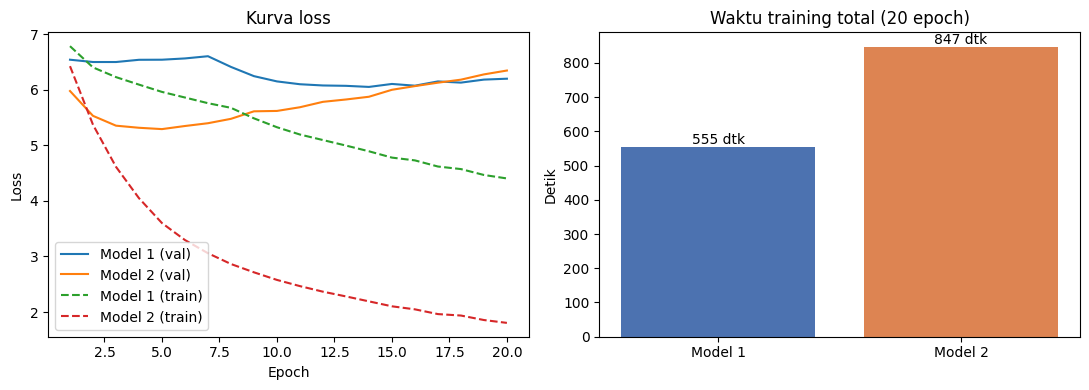

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].plot(range(1, EPOCHS + 1), hist1["val"], label="Model 1 (val)")
axs[0].plot(range(1, EPOCHS + 1), hist2["val"], label="Model 2 (val)")
axs[0].plot(range(1, EPOCHS + 1), hist1["train"], "--", label="Model 1 (train)")
axs[0].plot(range(1, EPOCHS + 1), hist2["train"], "--", label="Model 2 (train)")
axs[0].set_xlabel("Epoch"); axs[0].set_ylabel("Loss"); axs[0].set_title("Kurva loss"); axs[0].legend()
axs[1].bar(["Model 1", "Model 2"], [time1, time2], color=["#4c72b0", "#dd8452"])
for i, v in enumerate([time1, time2]):
    axs[1].text(i, v, f"{v:.0f} dtk", ha="center", va="bottom")
axs[1].set_ylabel("Detik"); axs[1].set_title(f"Waktu training total ({EPOCHS} epoch)")
plt.tight_layout(); plt.savefig("fig_loss_waktu.png", dpi=150); plt.show()

## 11. Evaluasi: Decoding, BLEU, dan Perbandingan Panjang Kalimat
**Decoding.** Terjemahan dihasilkan dengan *greedy decoding* (memilih kata berprobabilitas tertinggi pada setiap langkah) hingga `<eos>` atau 60 token, menggunakan parameter terbaik hasil validasi, pada data uji yang sama untuk kedua model.

**BLEU.** Skor BLEU *corpus-level* (n-gram 1–4 dengan *brevity penalty*) dihitung dengan implementasi sendiri tanpa library tambahan, secara keseluruhan, per kelompok panjang kalimat, dan per rentang panjang yang lebih halus. BLEU membandingkan kecocokan n-gram terhadap **satu** kalimat referensi sehingga terjemahan yang benar tetapi memakai pilihan kata berbeda dapat memperoleh skor rendah.

In [ ]:
def predict_all(model, loader):
    hyps = []
    for src, lens, _ in loader:
        ids, _ = model.translate(src.to(device), lens)
        hyps += [[trg_vocab.itos[i] for i in x] for x in ids]
    return hyps

def timed_predict(model):
    _sync(); t0 = time.time()
    h = predict_all(model, test_loader)
    _sync()
    return h, time.time() - t0

refs = [s.split() for s in test_df["en_clean"]]
hyps1, dec_time1 = timed_predict(model1)
hyps2, dec_time2 = timed_predict(model2)
print(f"Waktu decoding test: Model 1 {dec_time1:.1f} dtk | Model 2 {dec_time2:.1f} dtk")
print()

for i in range(3):
    print("SRC  :", test_df.loc[i, "id_clean"])
    print("REF  :", " ".join(refs[i]))
    print("M1   :", " ".join(hyps1[i]))
    print("M2   :", " ".join(hyps2[i]))
    print()

Waktu decoding test: Model 1 0.6 dtk | Model 2 1.2 dtk

SRC  : permainan keras pada game ke-12 kelihatannya akan membuat mahut menyamai kedudukan dan hal itu terbukti ketiga poin menjadi 6-6 sehingga terjadi tiebreak .
REF  : a close-fought 12th game saw mahut squander a chance to level at game point but he held his nerve to draw level at 6-6 and force a tie-break .
M1   : the was the the the the the the the the the the the the the the and and the the the the the the the the .
M2   : the game in the game game will be the game to the and and the third and the third <unk> points to the the .

SRC  : pegolf dari amerika , boo weekley , yang meraih gelar tahun lalu secaras spektakuler karena menyelamatkan pukulannya pada dua lubang terakhir , membuat empat birdie dengan angka 69 .
REF  : american boo weekley , who won last year's title with spectacular chip-ins to save par on the final two holes , started with a four-birdie 69 .
M1   : the <unk> <unk> , <unk> , <unk> , <unk> , <unk> <unk> 

In [ ]:
def ngrams(tokens, n):
    return collections.Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def bleu_scores(refs, hyps, max_n=4):
    clip, tot, rl, hl = [0] * max_n, [0] * max_n, 0, 0
    for r, h in zip(refs, hyps):
        rl += len(r); hl += len(h)
        for n in range(1, max_n + 1):
            hn, rn = ngrams(h, n), ngrams(r, n)
            clip[n - 1] += sum(min(c, rn[g]) for g, c in hn.items())
            tot[n - 1] += max(len(h) - n + 1, 0)

    p = [c / t if t > 0 else 0.0 for c, t in zip(clip, tot)]      # precision p1..p4
    bp = 0.0 if hl == 0 else (1.0 if hl > rl else math.exp(1 - rl / hl))

    scores = {}
    for n in range(1, max_n + 1):
        if min(p[:n]) == 0:
            scores[f"BLEU-{n}"] = 0.0
        else:
            scores[f"BLEU-{n}"] = bp * math.exp(sum(math.log(x) for x in p[:n]) / n)
    return scores

# ---- kelompok panjang (kelompok utama + rentang halus) ----
FINE_BINS = [(1, 12), (13, 18), (19, 24), (25, 30), (31, 40)]
def fine_label(lo, hi):
    return f"{lo}-{hi}"

groups_main = {b: test_df.index[test_df["bucket"] == b].tolist() for b in BUCKETS}
groups_fine = {fine_label(lo, hi): test_df.index[(test_df["len"] >= lo) & (test_df["len"] <= hi)].tolist()
               for lo, hi in FINE_BINS}
groups_main = {k: v for k, v in groups_main.items() if v}
groups_fine = {k: v for k, v in groups_fine.items() if v}

def len_ratio(rs, hs):
    return sum(len(h) for h in hs) / max(sum(len(r) for r in rs), 1)

def group_eval(groups):
    rows = {}
    for g, ids in groups.items():
        rs = [refs[i] for i in ids]
        b1, b2 = bleu_scores(rs, [hyps1[i] for i in ids]), bleu_scores(rs, [hyps2[i] for i in ids])
        rows[g] = {"n kalimat": len(ids),
                   "M1 BLEU-1": b1["BLEU-1"], "M1 BLEU-4": b1["BLEU-4"], "M1 rasio panjang": len_ratio(rs, [hyps1[i] for i in ids]),
                   "M2 BLEU-1": b2["BLEU-1"], "M2 BLEU-4": b2["BLEU-4"], "M2 rasio panjang": len_ratio(rs, [hyps2[i] for i in ids])}
    out = pd.DataFrame(rows).T
    out["n kalimat"] = out["n kalimat"].astype(int)
    return out

hasil = pd.DataFrame({M1: bleu_scores(refs, hyps1), M2: bleu_scores(refs, hyps2)}).T
print("BLEU keseluruhan (test):")
display(hasil.round(4))

tab_bucket = group_eval(groups_main)
tab_fine = group_eval(groups_fine)
print("\nBLEU per kelompok panjang (rasio panjang = total token hasil / total token referensi):")
display(tab_bucket.round(4))
print("\nBLEU per rentang panjang kalimat sumber (token):")
display(tab_fine.round(4))

BLEU keseluruhan (test):


,BLEU-1,BLEU-2,BLEU-3,BLEU-4
Model 1 (tanpa attention),0.1952,0.063,0.0239,0.0113
Model 2 (+ attention),0.3370,0.171,0.0921,0.0513



BLEU per kelompok panjang (rasio panjang = total token hasil / total token referensi):


,n kalimat,M1 BLEU-1,M1 BLEU-4,M1 rasio panjang,M2 BLEU-1,M2 BLEU-4,M2 rasio panjang
pendek (<=12),352,0.2435,0.0088,0.9147,0.3669,0.0587,0.9534
sedang (13-24),986,0.2062,0.0108,0.9613,0.3414,0.0519,0.9227
panjang (>=25),816,0.1788,0.0117,0.9640,0.3289,0.0498,0.9031



BLEU per rentang panjang kalimat sumber (token):


,n kalimat,M1 BLEU-1,M1 BLEU-4,M1 rasio panjang,M2 BLEU-1,M2 BLEU-4,M2 rasio panjang
1-12,352,0.2435,0.0088,0.9147,0.3669,0.0587,0.9534
13-18,488,0.2135,0.0124,0.9422,0.3527,0.0561,0.9260
19-24,498,0.2008,0.0096,0.9754,0.3331,0.0489,0.9202
25-30,451,0.1863,0.0128,0.9845,0.3337,0.0517,0.9017
31-40,365,0.1708,0.0105,0.9421,0.3238,0.0477,0.9046


### 11.1 Uji Perbedaan BLEU-4 (Paired Bootstrap)
Perbedaan BLEU-4 antar-model diuji dengan *paired bootstrap* 1.000 kali: kalimat uji diambil ulang dengan pengembalian dan prediksi kedua model untuk kalimat terpilih diambil **bersama-sama**. Interval kepercayaan 95% yang dihasilkan menggambarkan ketidakpastian akibat variasi pengambilan sampel data uji dengan model yang sudah dilatih tetap sama. Interval ini **tidak** mengukur variasi akibat *seed* training, karena setiap model dilatih satu kali (seed 42).

In [ ]:
# ---- Paired bootstrap: apakah selisih BLEU-4 Model 2 - Model 1 bermakna? ----
def sent_stats(r, h, max_n=4):
    clip, tot = [], []
    for n in range(1, max_n + 1):
        hn, rn = ngrams(h, n), ngrams(r, n)
        clip.append(sum(min(c, rn[g]) for g, c in hn.items()))
        tot.append(max(len(h) - n + 1, 0))
    return clip + tot + [len(r), len(h)]

def bleu4_from_sums(S):
    """S: array [..., 10] berisi jumlah (clip1-4, tot1-4, panjang ref, panjang hyp)."""
    S = np.asarray(S, dtype=float)
    clip, tot, rl, hl = S[..., 0:4], S[..., 4:8], S[..., 8], S[..., 9]
    p = clip / np.maximum(tot, 1)
    ok = (p > 0).all(axis=-1) & (hl > 0)
    bp = np.where(hl > rl, 1.0, np.exp(1 - rl / np.maximum(hl, 1)))
    return np.where(ok, bp * np.exp(np.log(np.maximum(p, 1e-12)).mean(axis=-1)), 0.0)

stats1 = np.array([sent_stats(r, h) for r, h in zip(refs, hyps1)])
stats2 = np.array([sent_stats(r, h) for r, h in zip(refs, hyps2)])
assert abs(float(bleu4_from_sums(stats1.sum(0))) - hasil.loc[M1, "BLEU-4"]) < 1e-9
assert abs(float(bleu4_from_sums(stats2.sum(0))) - hasil.loc[M2, "BLEU-4"]) < 1e-9

def paired_bootstrap(st1, st2, n_boot=1000, seed=SEED):
    rng = np.random.RandomState(seed)
    N = len(st1); diffs = []
    for _ in range(n_boot // 100):
        ix = rng.randint(0, N, size=(100, N))
        diffs.append(bleu4_from_sums(st2[ix].sum(1)) - bleu4_from_sums(st1[ix].sum(1)))
    return np.concatenate(diffs)

boot = paired_bootstrap(stats1, stats2)
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])
p_m2_better = float((boot > 0).mean())
print(f"Selisih BLEU-4 (Model 2 - Model 1): {100*(hasil.loc[M2,'BLEU-4']-hasil.loc[M1,'BLEU-4']):+.2f} poin")
print(f"Interval kepercayaan 95% (bootstrap 1000x): [{100*ci_lo:+.2f}, {100*ci_hi:+.2f}] poin")
print(f"Proporsi resampling di mana Model 2 > Model 1: {100*p_m2_better:.1f}%")
print("Catatan: interval ini hanya mencerminkan variasi sampel data test, bukan variasi seed training (kedua model dilatih satu kali, seed 42).")

Selisih BLEU-4 (Model 2 - Model 1): +4.00 poin
Interval kepercayaan 95% (bootstrap 1000x): [+3.69, +4.34] poin
Proporsi resampling di mana Model 2 > Model 1: 100.0%
Catatan: interval ini hanya mencerminkan variasi sampel data test, bukan variasi seed training (kedua model dilatih satu kali, seed 42).


### 11.2 Perbandingan BLEU-4 menurut Kelompok Panjang Kalimat
Tabel berikut memuat skor BLEU-4 absolut kedua model pada setiap kelompok panjang, selisih absolut (Model 2 − Model 1), model dengan skor lebih tinggi, serta interval bootstrap 95% untuk selisih pada kelompok tersebut. Skor absolut, selisih antar-model, dan pola perubahan skor terhadap panjang kalimat diperlakukan sebagai informasi yang terpisah.

In [ ]:
records = {}
for b, ids in groups_main.items():
    ids = np.array(ids)
    s1_, s2_ = float(bleu4_from_sums(stats1[ids].sum(0))), float(bleu4_from_sums(stats2[ids].sum(0)))
    lo_, hi_ = np.percentile(paired_bootstrap(stats1[ids], stats2[ids]), [2.5, 97.5])
    records[b] = {"n kalimat": len(ids), "BLEU-4 Model 1": 100 * s1_, "BLEU-4 Model 2": 100 * s2_,
                  "Selisih (Model 2 - Model 1)": 100 * (s2_ - s1_),
                  "Model dengan BLEU-4 lebih tinggi": "Model 2" if s2_ - s1_ > 1e-12 else ("Model 1" if s1_ - s2_ > 1e-12 else "setara"),
                  "CI 95% selisih (bawah)": 100 * lo_, "CI 95% selisih (atas)": 100 * hi_}
tab_len = pd.DataFrame(records).T
for c_ in ["n kalimat"]:
    tab_len[c_] = tab_len[c_].astype(int)
for c_ in ["BLEU-4 Model 1", "BLEU-4 Model 2", "Selisih (Model 2 - Model 1)", "CI 95% selisih (bawah)", "CI 95% selisih (atas)"]:
    tab_len[c_] = tab_len[c_].astype(float)
print("BLEU-4 (poin, skala 0-100) per kelompok panjang kalimat sumber:")
display(tab_len.round(2))

BLEU-4 (poin, skala 0-100) per kelompok panjang kalimat sumber:


,n kalimat,BLEU-4 Model 1,BLEU-4 Model 2,Selisih (Model 2 - Model 1),Model dengan BLEU-4 lebih tinggi,CI 95% selisih (bawah),CI 95% selisih (atas)
pendek (<=12),352,0.88,5.87,4.99,Model 2,3.94,6.57
sedang (13-24),986,1.08,5.19,4.11,Model 2,3.63,4.62
panjang (>=25),816,1.17,4.98,3.80,Model 2,3.33,4.26


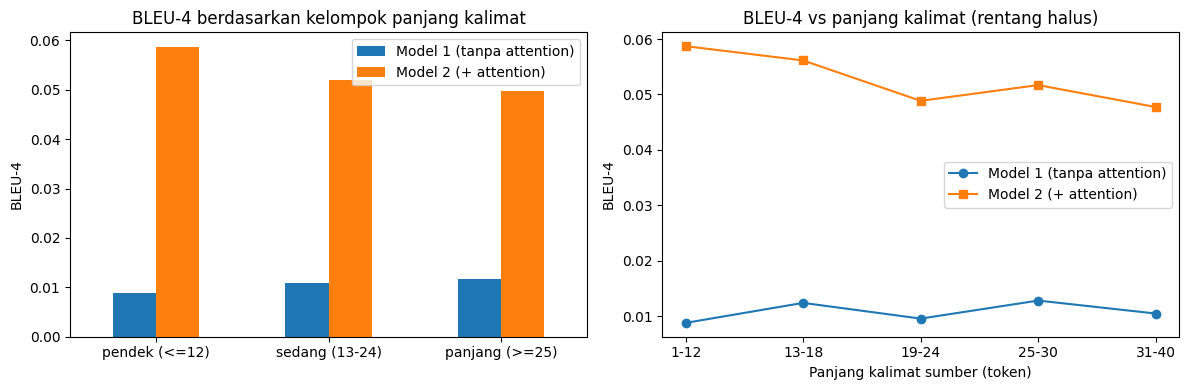

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
tab_bucket[["M1 BLEU-4", "M2 BLEU-4"]].rename(columns={"M1 BLEU-4": M1, "M2 BLEU-4": M2}).plot(kind="bar", ax=axs[0], rot=0)
axs[0].set_ylabel("BLEU-4"); axs[0].set_title("BLEU-4 berdasarkan kelompok panjang kalimat")
axs[1].plot(tab_fine.index, tab_fine["M1 BLEU-4"], "o-", label=M1)
axs[1].plot(tab_fine.index, tab_fine["M2 BLEU-4"], "s-", label=M2)
axs[1].set_xlabel("Panjang kalimat sumber (token)"); axs[1].set_ylabel("BLEU-4")
axs[1].set_title("BLEU-4 vs panjang kalimat (rentang halus)"); axs[1].legend()
plt.tight_layout(); plt.savefig("fig_bleu_per_panjang.png", dpi=150); plt.show()

## 12. Contoh Prediksi dan Evaluasi Kualitatif Berbasis Kemiripan Referensi
Contoh dipilih **secara otomatis** dari data uji. Kemiripan antara hasil terjemahan dan kalimat referensi diukur dengan **chrF** tingkat kalimat (n-gram karakter 1–6, spasi diabaikan, β = 2; rentang 0–1).

chrF dan BLEU adalah ukuran **kemiripan teks** terhadap satu referensi, bukan penilaian kesesuaian makna secara menyeluruh. Terjemahan yang bermakna benar tetapi memakai sinonim dapat memperoleh skor rendah, sedangkan kalimat dengan banyak karakter yang sama belum tentu bermakna benar. Penilaian kualitas makna secara utuh memerlukan evaluasi semantik yang tidak sepenuhnya diwakili oleh kedua metrik ini. Karena itu kategori yang dipakai bersifat deskriptif: **kemiripan referensi relatif tinggi** (skor ≥ kuartil ke-3 dari seluruh skor chrF kedua model pada data uji), **relatif rendah** (skor ≤ kuartil ke-1), dan **menengah**. Kecocokan persis dengan referensi dilaporkan sebagai informasi tambahan apabila ada.

Pada setiap kelompok panjang dipilih: (1) kalimat dengan rata-rata chrF kedua model tertinggi, (2) terendah, (3) kalimat dengan selisih chrF terbesar yang menguntungkan Model 2, dan (4) yang menguntungkan Model 1. Setiap kalimat hanya muncul satu kali.

In [ ]:
def chrf(ref_tokens, hyp_tokens, n_max=6, beta=2.0):
    """chrF sentence-level (n-gram karakter 1-6, spasi diabaikan, beta=2), rentang 0-1."""
    r, h = "".join(ref_tokens), "".join(hyp_tokens)
    if not r or not h:
        return 0.0
    precs, recs = [], []
    for n in range(1, n_max + 1):
        rn = collections.Counter(r[i:i + n] for i in range(len(r) - n + 1))
        hn = collections.Counter(h[i:i + n] for i in range(len(h) - n + 1))
        if not rn or not hn:
            continue
        match = sum((rn & hn).values())
        precs.append(match / sum(hn.values())); recs.append(match / sum(rn.values()))
    if not precs:
        return 0.0
    p, rc = float(np.mean(precs)), float(np.mean(recs))
    return 0.0 if p + rc == 0 else (1 + beta ** 2) * p * rc / (beta ** 2 * p + rc)

sc1 = np.array([chrf(r, h) for r, h in zip(refs, hyps1)])
sc2 = np.array([chrf(r, h) for r, h in zip(refs, hyps2)])
exact1 = np.array([r == h for r, h in zip(refs, hyps1)])
exact2 = np.array([r == h for r, h in zip(refs, hyps2)])

q_lo, q_hi = np.percentile(np.concatenate([sc1, sc2]), [25, 75])
def kategori(s):
    return "kemiripan referensi relatif tinggi" if s >= q_hi else ("kemiripan referensi relatif rendah" if s <= q_lo else "kemiripan referensi menengah")
print(f"Ambang kategori (dari distribusi chrF kedua model pada data uji): relatif rendah <= {q_lo:.3f} | relatif tinggi >= {q_hi:.3f}")

rows = {}
for b, ids in list(groups_main.items()) + [("TOTAL", list(range(len(refs))))]:
    ids = np.array(ids)
    rows[b] = {"n": len(ids), "M1 kecocokan persis": int(exact1[ids].sum()), "M2 kecocokan persis": int(exact2[ids].sum()),
               "M1 kemiripan relatif tinggi": int((sc1[ids] >= q_hi).sum()), "M2 kemiripan relatif tinggi": int((sc2[ids] >= q_hi).sum()),
               "M1 kemiripan relatif rendah": int((sc1[ids] <= q_lo).sum()), "M2 kemiripan relatif rendah": int((sc2[ids] <= q_lo).sum()),
               "M1 chrF rata-rata": float(sc1[ids].mean()), "M2 chrF rata-rata": float(sc2[ids].mean())}
tab_sim = pd.DataFrame(rows).T
for c_ in tab_sim.columns:
    if "chrF" not in c_:
        tab_sim[c_] = tab_sim[c_].astype(int)
print("\nRingkasan kemiripan referensi per kelompok panjang (jumlah kalimat uji pada setiap kategori):")
display(tab_sim.round(3))

mean_sc = (sc1 + sc2) / 2
used, picked = set(), []
def pick(ids, key, reverse=True, need_positive=False):
    for i in sorted(ids, key=lambda k: (key(k), -k) if reverse else (key(k), k), reverse=reverse):
        if need_positive and key(i) <= 0:
            return None
        if i not in used:
            used.add(i); return i
    return None

spec = [("rata-rata chrF kedua model tertinggi", lambda i: mean_sc[i], True, False),
        ("rata-rata chrF kedua model terendah", lambda i: mean_sc[i], False, False),
        ("selisih terbesar: Model 2 lebih mirip referensi", lambda i: sc2[i] - sc1[i], True, True),
        ("selisih terbesar: Model 1 lebih mirip referensi", lambda i: sc1[i] - sc2[i], True, True)]
for b, ids in groups_main.items():
    for jenis, key, rev, pos in spec:
        i = pick(ids, key, rev, pos)
        if i is not None:
            picked.append((b, jenis, i))
exact_idx = [i for i in range(len(refs)) if (exact1[i] or exact2[i]) and i not in used][:3]
for i in exact_idx:
    used.add(i); picked.append((test_df.loc[i, "bucket"], "kecocokan persis dengan referensi (informasi tambahan)", i))
if not exact_idx and not (exact1.any() or exact2.any()):
    print("\nTidak ditemukan prediksi yang identik dengan referensi pada data uji.")

tab_contoh = pd.DataFrame([{
    "kelompok panjang": b, "dasar pemilihan": jenis, "indeks uji": i, "panjang sumber (token)": int(test_df.loc[i, "len"]),
    "kalimat sumber (Indonesia)": test_df.loc[i, "id_clean"], "referensi (Inggris)": " ".join(refs[i]),
    "prediksi Model 1": " ".join(hyps1[i]), "prediksi Model 2": " ".join(hyps2[i]),
    "chrF Model 1": round(float(sc1[i]), 3), "chrF Model 2": round(float(sc2[i]), 3),
    "kategori Model 1": kategori(sc1[i]), "kategori Model 2": kategori(sc2[i])} for b, jenis, i in picked])
tab_contoh.to_csv("contoh_prediksi_terpilih.csv", index=False)
print(f"\nTabel contoh prediksi terpilih ({len(tab_contoh)} contoh):")
with pd.option_context("display.max_colwidth", None, "display.width", 250):
    display(tab_contoh)

Ambang kategori (dari distribusi chrF kedua model pada data uji): relatif rendah <= 0.087 | relatif tinggi >= 0.236

Ringkasan kemiripan referensi per kelompok panjang (jumlah kalimat uji pada setiap kategori):


,n,M1 kecocokan persis,M2 kecocokan persis,M1 kemiripan relatif tinggi,M2 kemiripan relatif tinggi,M1 kemiripan relatif rendah,M2 kemiripan relatif rendah,M1 chrF rata-rata,M2 chrF rata-rata
pendek (<=12),352,0,0,16,154,141,34,0.110,0.239
sedang (13-24),986,0,0,31,450,441,40,0.106,0.240
panjang (>=25),816,0,0,28,398,392,29,0.102,0.237
TOTAL,2154,0,0,75,1002,974,103,0.106,0.239



Tidak ditemukan prediksi yang identik dengan referensi pada data uji.

Tabel contoh prediksi terpilih (12 contoh):


,kelompok panjang,dasar pemilihan,indeks uji,panjang sumber (token),kalimat sumber (Indonesia),referensi (Inggris),prediksi Model 1,prediksi Model 2,chrF Model 1,chrF Model 2,kategori Model 1,kategori Model 2
0,pendek (<=12),rata-rata chrF kedua model tertinggi,996,5,ada dua teori utama .,there are two main theories .,there are no <unk> of .,there are two two main .,0.295,0.602,kemiripan referensi relatif tinggi,kemiripan referensi relatif tinggi
1,pendek (<=12),rata-rata chrF kedua model terendah,324,8,"halida mujani bersama diplomat senior soemadi brotodiningrat ,",the 30-member delegation was led by senior diplomat soemadi dm brotodiningrat and halida mujani .,<unk> <unk> <unk> <unk> <unk> <unk> <unk> .,<unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .,0.018,0.018,kemiripan referensi relatif rendah,kemiripan referensi relatif rendah
2,pendek (<=12),selisih terbesar: Model 2 lebih mirip referensi,41,12,pembentukan sayap juga memerlukan ? rancangan ? yang tersendiri dan sempurna .,the formation of wings also requires a distinct and flawless design .,the <unk> of the and and and and the and and .,the formation of wings also also requires a design of design and perfect design .,0.097,0.663,kemiripan referensi menengah,kemiripan referensi relatif tinggi
3,pendek (<=12),selisih terbesar: Model 1 lebih mirip referensi,198,5,itu pertandingan yang alot .,it was a tough match .,it was the <unk> .,the game .,0.208,0.066,kemiripan referensi menengah,kemiripan referensi relatif rendah
4,sedang (13-24),rata-rata chrF kedua model tertinggi,2105,13,lembaga keuangan mikro merupakan kelembagaan yang memfokuskan diri melayani para pengusaha mikro .,micro finance institution is institution focusing to serve micro businessmen .,micro finance institution micro finance institution is micro finance institution .,micro finance institution micro micro which is the to micro businessmen .,0.555,0.583,kemiripan referensi relatif tinggi,kemiripan referensi relatif tinggi
5,sedang (13-24),rata-rata chrF kedua model terendah,1638,15,"bahkan , keindahan sempurna bulu merak telah membuatnya ? sakit ? menurut istilahnya sendiri .","moreover , the perfect aesthetics of the peacock's feathers had made him sick his own words .","the , , , , <unk> , , <unk> <unk> , <unk> <unk> , <unk> <unk> .",even <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .,0.026,0.018,kemiripan referensi relatif rendah,kemiripan referensi relatif rendah
6,sedang (13-24),selisih terbesar: Model 2 lebih mirip referensi,1852,24,"bordeaux mengawali pertandingan dengan sempurna , mencetak dua gol dalam 22 menit melalui striker argentina fernando cavenaghi dan pemain tengah asal brazil fernando .","bordeaux made a perfect start , scoring two goals in 22 minutes through argentine striker fernando cavenaghi and brazilian midfielder fernando .",the <unk> scored a <unk> and and the the the the the the the the the the the the the the the the .,bordeaux bordeaux started with with with with a with two goals in the minutes through a <unk> fernando cavenaghi and brazilian midfielder fernando .,0.081,0.635,kemiripan referensi relatif rendah,kemiripan referensi relatif tinggi
7,sedang (13-24),selisih terbesar: Model 1 lebih mirip referensi,954,21,sebanyak 28 poin dan sembilan rebound dari antawn jamison membawa washington wizards meraih kemenangan kandang 101-84 atas new orleans hornets .,antawn jamison's 28 points and nine rebounds paced the washington wizards to a 101-84 home win over the new orleans hornets .,the <unk> scored a points from the points and the rebounds to the points and the rebounds .,pau and 28 points from <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> .,0.255,0.098,kemiripan referensi relatif tinggi,kemiripan referensi menengah
8,panjang (>=25),rata-rata chrF kedua model tertinggi,364,30,"dengan kematian-kematian terakhir itu , jumlah prajurit as yang tewas di irak sejak invasi maret 2003 menjadi 3 . 

## 13. Visualisasi Attention dan Alignment (Model 2)
Heatmap Attention menampilkan bobot yang diberikan decoder kepada setiap kata sumber pada saat menghasilkan setiap kata target.
- Sumbu horizontal: token sumber (Bahasa Indonesia), ditambah `<eos>`.
- Sumbu vertikal: token target (Bahasa Inggris) hasil terjemahan Model 2.
- Intensitas warna: besar bobot Attention (lebih terang berarti bobot lebih besar; setiap baris berjumlah 1).
- Bobot yang terfokus pada satu atau beberapa posisi menunjukkan perhatian model terkonsentrasi pada posisi sumber tersebut, sedangkan bobot yang menyebar menunjukkan perhatian yang terbagi.

Urutan kata Bahasa Indonesia dan Inggris dapat berbeda (misalnya "buku baru" menjadi "new book"), sehingga pola alignment tidak harus diagonal. Pola diagonal tidak otomatis menunjukkan alignment yang benar, dan pola non-diagonal tidak otomatis menunjukkan alignment yang salah. Heatmap dipakai sebagai alat interpretasi kualitatif, bukan sebagai bukti tunggal kualitas terjemahan.

Kalimat yang divisualisasikan dipilih tanpa memandang kualitas terjemahan: kalimat dengan panjang median pada setiap kelompok panjang, kalimat uji terpanjang, dan satu kalimat tambahan di luar data uji.

Kelompok pendek (<=12) | kalimat uji #352 (10 token) | REF: we have played a few times and know each other pretty well .


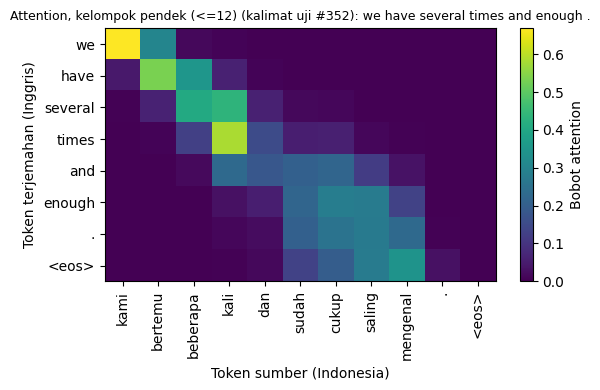

Kelompok sedang (13-24) | kalimat uji #233 (19 token) | REF: the sea sponge has an interwoven skeletal structure made up of glass-fibres and slim pin-like structures .


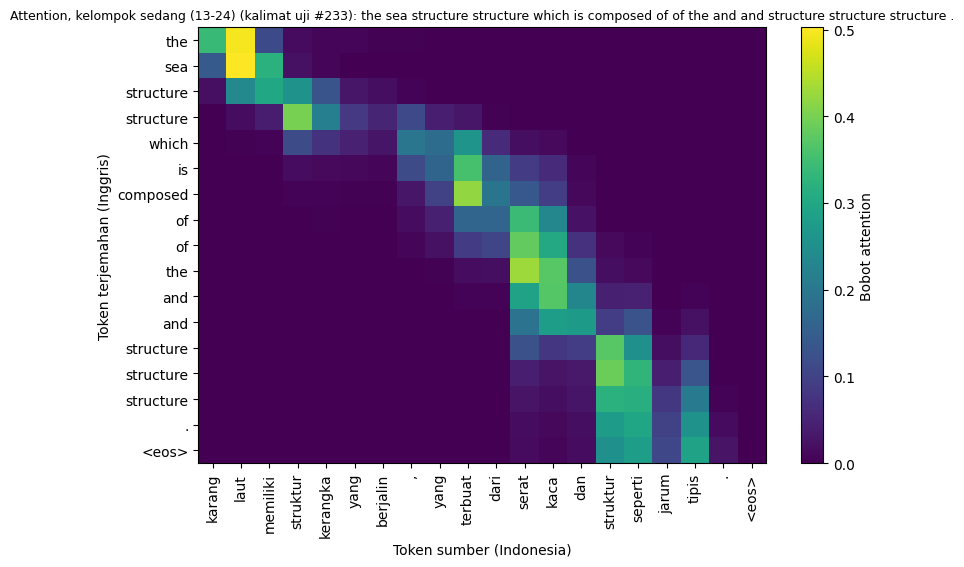

Kelompok panjang (>=25) | kalimat uji #575 (30 token) | REF: witnesses told turkish television the building had been damaged in an earthquake in 1999 which killed around 18 , 000 people in northwest turkey .


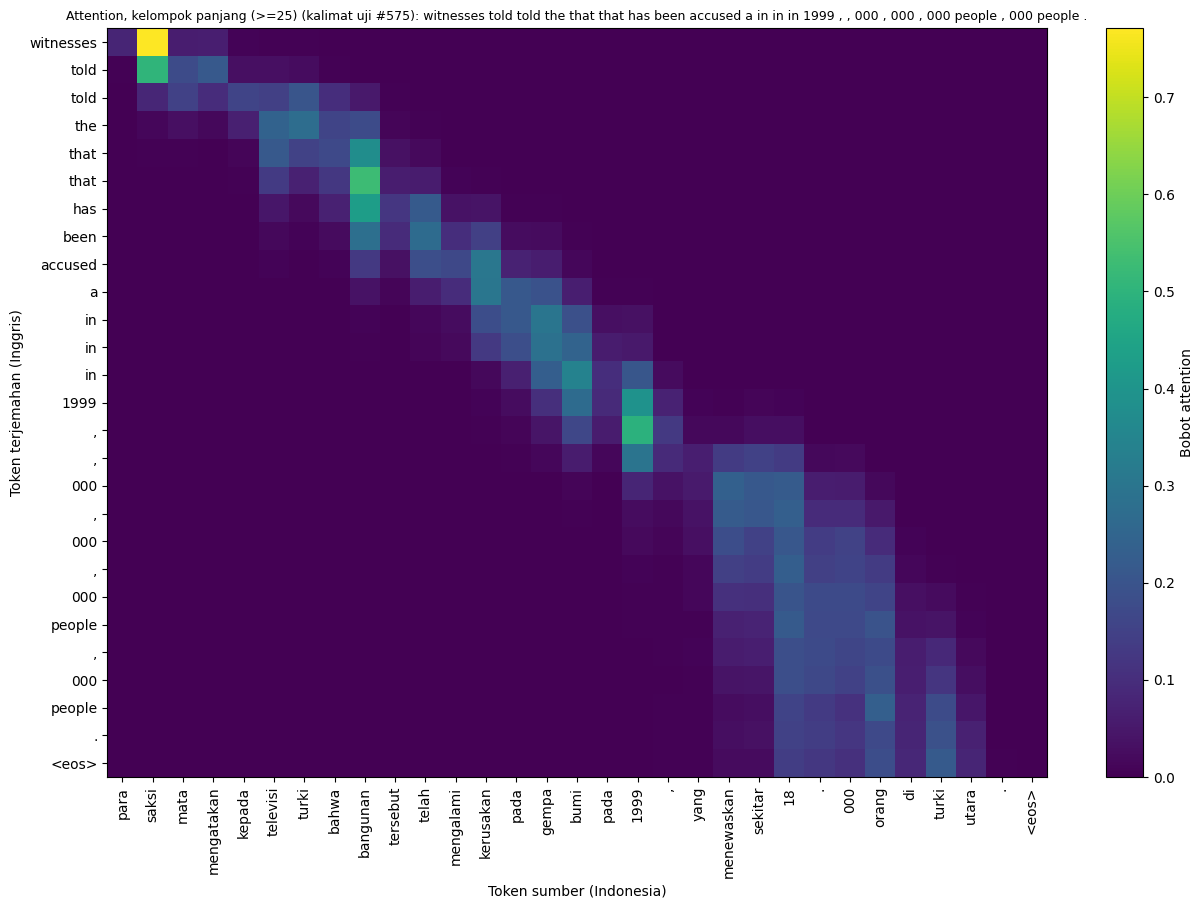

Kalimat uji terpanjang (40 token) | REF: the two accords were a management agreement and an offtake for crude palm oil in bulk agreement , fitri barnas , unsp's corporate secretary , said in a report to the jakarta stock exchange on wednesday .


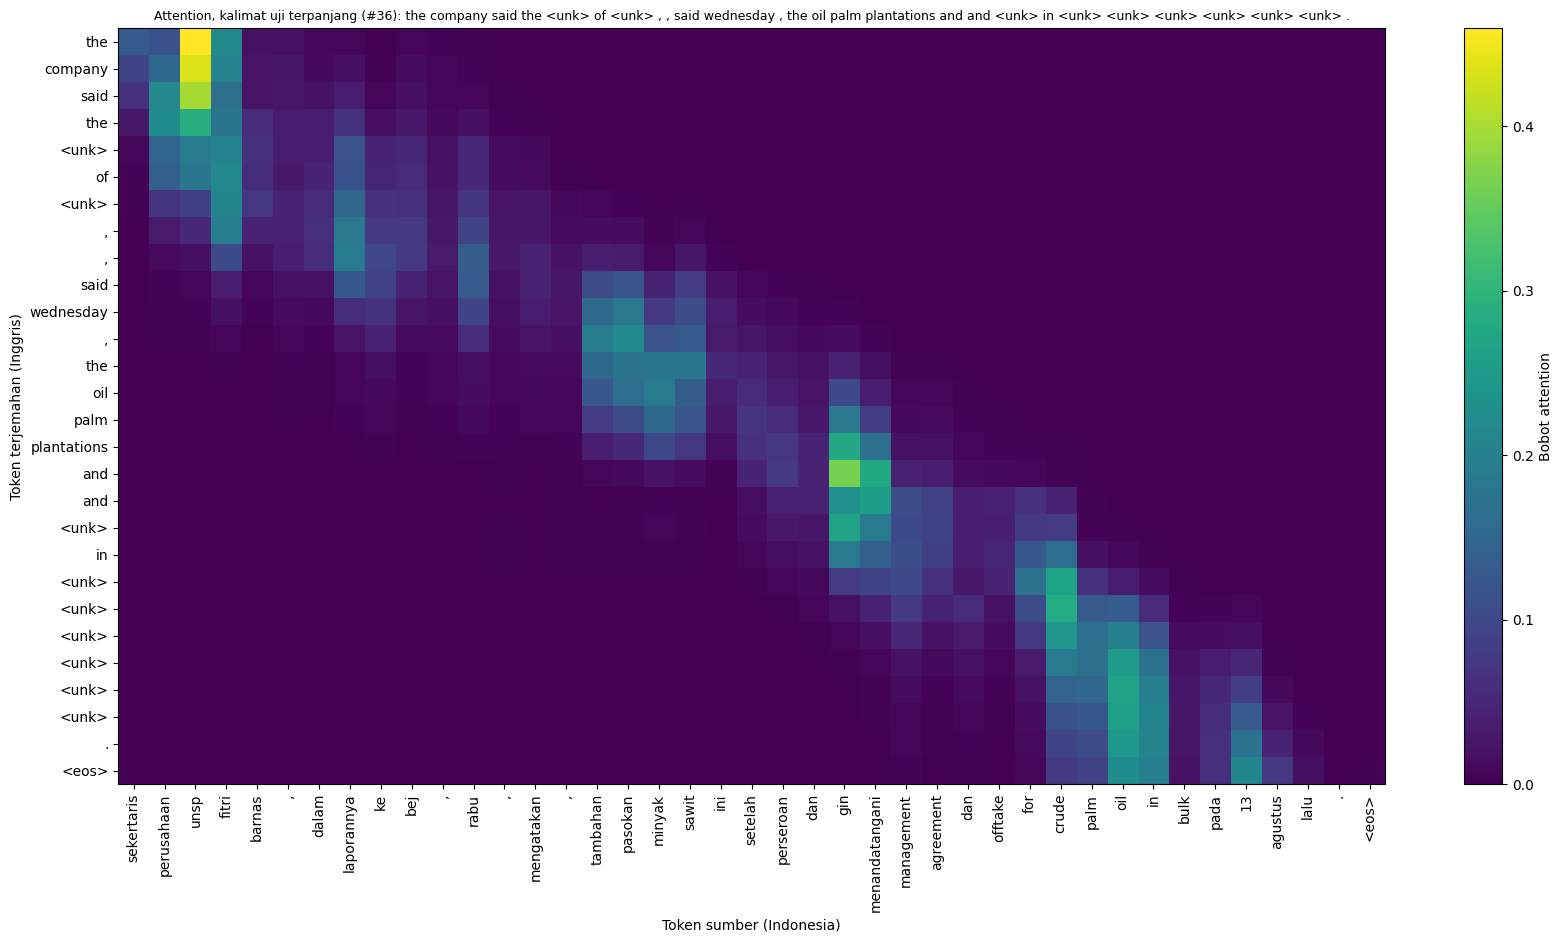

Kalimat tambahan di luar data uji: Presiden mengatakan pemerintah akan menaikkan harga bahan bakar minyak pada bulan depan.


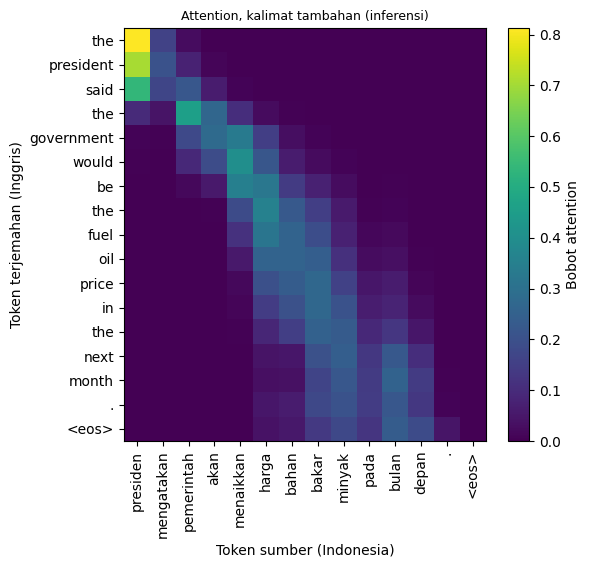

In [ ]:
def draw_attention(attn, xl, yl, ax=None, title=None, save=None):
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(max(6, len(xl) * 0.42), max(4, len(yl) * 0.34)))
    else:
        fig = ax.figure
    im = ax.imshow(attn, cmap="viridis", aspect="auto", vmin=0.0, vmax=max(float(attn.max()), 1e-9))
    ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl, rotation=90)
    ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl)
    ax.set_xlabel("Token sumber (Indonesia)"); ax.set_ylabel("Token terjemahan (Inggris)")
    ax.set_title(title if title is not None else " ".join(yl[:-1]), fontsize=9)
    fig.colorbar(im, ax=ax, label="Bobot attention")
    if show:
        plt.tight_layout()
        if save:
            plt.savefig(save, dpi=150, bbox_inches="tight")
        plt.show()

def plot_attention(model, sentence, ax=None, title=None, save=None):
    s = clean(sentence)
    ids = src_vocab.encode(s) + [EOS]
    src = torch.tensor([ids], device=device)
    lens = torch.tensor([len(ids)])
    pred, attn = model.translate(src, lens)
    pred, attn = pred[0], attn[0]
    T = min(len(pred) + 1, attn.shape[0])                 # termasuk <eos>
    attn = attn[:T, :len(ids)]
    xl = s.split() + ["<eos>"]
    yl = ([trg_vocab.itos[i] for i in pred] + ["<eos>"])[:T]
    draw_attention(attn, xl, yl, ax=ax, title=title, save=save)

def median_len_idx(ids):
    ordered = sorted(ids, key=lambda i: (int(test_df.loc[i, "len"]), i))
    return ordered[len(ordered) // 2]

for b, ids in groups_main.items():
    i = median_len_idx(ids)
    print(f"Kelompok {b} | kalimat uji #{i} ({int(test_df.loc[i, 'len'])} token) | REF: {' '.join(refs[i])}")
    plot_attention(model2, test_df.loc[i, "id"], title=f"Attention, kelompok {b} (kalimat uji #{i}): " + " ".join(hyps2[i]),
                   save=f"fig_attention_{b.split()[0]}.png")

i_max = int(test_df["len"].idxmax())
print(f"Kalimat uji terpanjang ({int(test_df.loc[i_max, 'len'])} token) | REF: {' '.join(refs[i_max])}")
plot_attention(model2, test_df.loc[i_max, "id"], title=f"Attention, kalimat uji terpanjang (#{i_max}): " + " ".join(hyps2[i_max]),
               save="fig_attention_terpanjang.png")

kalimat_tambahan = "Presiden mengatakan pemerintah akan menaikkan harga bahan bakar minyak pada bulan depan."
print("Kalimat tambahan di luar data uji:", kalimat_tambahan)
plot_attention(model2, kalimat_tambahan, title="Attention, kalimat tambahan (inferensi)", save="fig_attention_tambahan.png")

### 13.1 Konsentrasi Attention (Analisis Tambahan)
Sebagai informasi pelengkap heatmap dihitung **entropi Attention** ternormalisasi untuk setiap kalimat uji (0 = bobot sepenuhnya pada satu posisi sumber, 1 = bobot merata di seluruh posisi). Entropi hanya menggambarkan seberapa terkonsentrasi bobot Attention; ukuran ini bukan ukuran kebenaran alignment maupun kualitas terjemahan. Pada tahap yang sama diperiksa bahwa bobot Attention setiap langkah decoder berjumlah 1 dan bahwa posisi `<pad>` tidak memperoleh bobot.

In [ ]:
def attention_stats(model, loader):
    """Entropi attention ternormalisasi per kalimat, serta pemeriksaan normalisasi dan mask padding."""
    ent, max_dev, max_pad = [], 0.0, 0.0
    for src, lens, _ in loader:
        ids, attn = model.translate(src.to(device), lens)
        for b in range(len(ids)):
            S, T = int(lens[b]), len(ids[b])
            max_dev = max(max_dev, float(np.abs(attn[b].sum(-1) - 1.0).max()))      # jumlah bobot tiap langkah = 1
            max_pad = max(max_pad, float(attn[b][:, S:].sum(-1).max()) if attn.shape[2] > S else 0.0)   # bobot pada <pad> = 0
            if T == 0 or S < 2:
                ent.append(np.nan); continue
            a = attn[b, :T, :S]
            a = a / a.sum(1, keepdims=True)
            ent.append(float((-(a * np.log(a + 1e-12)).sum(1) / np.log(S)).mean()))
    return np.array(ent), max_dev, max_pad

att_ent, att_dev_sum, att_pad_mass = attention_stats(model2, test_loader)

In [ ]:
print(f"Pemeriksaan Attention pada seluruh data uji: penyimpangan maksimum jumlah bobot dari 1 = {att_dev_sum:.2e}; bobot maksimum pada posisi <pad> = {att_pad_mass:.2e}")
print("Normalisasi dan mask padding:", "sesuai" if (att_dev_sum < 1e-3 and att_pad_mass < 1e-6) else "TIDAK SESUAI, perlu diperiksa")

rows = {"SEMUA": {"entropi attention (0-1)": np.nanmean(att_ent)}}
for b, ids in groups_main.items():
    rows[b] = {"entropi attention (0-1)": np.nanmean(att_ent[ids])}
tab_att = pd.DataFrame(rows).T
print("\nKonsentrasi Attention Model 2 per kelompok panjang (rendah = terfokus, tinggi = menyebar):")
display(tab_att.round(4))

Pemeriksaan Attention pada seluruh data uji: penyimpangan maksimum jumlah bobot dari 1 = 2.38e-07; bobot maksimum pada posisi <pad> = 0.00e+00
Normalisasi dan mask padding: sesuai

Konsentrasi Attention Model 2 per kelompok panjang (rendah = terfokus, tinggi = menyebar):


,entropi attention (0-1)
SEMUA,0.5489
pendek (<=12),0.5331
sedang (13-24),0.5463
panjang (>=25),0.5588


## 14. Analisis Error

Setiap hasil terjemahan pada data uji dibandingkan dengan kalimat referensi menggunakan `difflib.SequenceMatcher`. Perbandingan ini digunakan untuk mengidentifikasi tiga jenis ketidaksesuaian token, yaitu substitusi kata, kata yang hilang, dan kata berlebih. Jumlah setiap jenis error dinormalisasi berdasarkan 100 kata referensi agar hasil kedua model dapat dibandingkan.

Analisis tambahan mencakup kata referensi yang paling sering tidak cocok, tingkat ketidakcocokan token berdasarkan posisi dalam kalimat (awal hingga akhir), serta gejala kegagalan model sekuens. Gejala tersebut meliputi kemunculan token `<unk>`, pengulangan frasa (*loop*), keluaran yang mencapai batas maksimum 60 token tanpa menghasilkan `<eos>`, dan rasio panjang keluaran terhadap referensi.

Deteksi *loop* didefinisikan sebagai kemunculan bigram berturut-turut yang sama sebanyak tiga kali atau lebih. Analisis posisi kata didasarkan pada token referensi yang tidak cocok dengan hasil prediksi. Oleh karena itu, hasil analisis ini merupakan indikator kesalahan berbasis pencocokan token dan tidak sepenuhnya merepresentasikan kesalahan semantik maupun tata bahasa.

Jenis error, seluruh test (jumlah kata dan per 100 kata referensi)


,Model 1,Model 2,Model 1 /100 kata,Model 2 /100 kata
substitusi kata,29924,27984,60.5,56.6
kata hilang,11010,7148,22.3,14.5
kata berlebih,1345,2992,2.7,6.1



Kata referensi yang paling sering salah - Model 1: [('in', 983), ('to', 915), ('of', 859), ('a', 841), (',', 695), ('the', 591), ('and', 551), ('on', 433), ('for', 361), ('is', 322)]
Kata referensi yang paling sering salah - Model 2: [('the', 818), ('to', 765), (',', 751), ('of', 728), ('a', 680), ('in', 650), ('on', 410), ('for', 319), ('and', 308), ('is', 308)]

Gejala kegagalan per kelompok panjang:


,,token <unk> (%),kalimat berulang/loop (%),tidak berhenti (max_len) (%),rasio panjang hasil/ref
SEMUA,M1,12.38,81.52,0.09,0.96
pendek (<=12),M1,14.45,42.33,0.00,0.91
sedang (13-24),M1,12.96,83.77,0.00,0.96
panjang (>=25),M1,11.61,95.71,0.25,0.96
SEMUA,M2,13.29,53.53,0.37,0.92
pendek (<=12),M2,9.52,21.02,0.00,0.95
sedang (13-24),M2,12.97,49.09,0.51,0.92
panjang (>=25),M2,14.15,72.92,0.37,0.90



Jenis error per kelompok panjang (per 100 kata referensi):


substitusi kata  kata hilang  kata berlebih
pendek (<=12)  M1             66.8         10.0            2.9
               M2             54.8         10.4            5.6
sedang (13-24) M1             62.0         19.6            3.0
               M2             55.7         14.1            5.7
panjang (>=25) M1             58.4         26.3            2.5
               M2             57.6         15.3            6.4

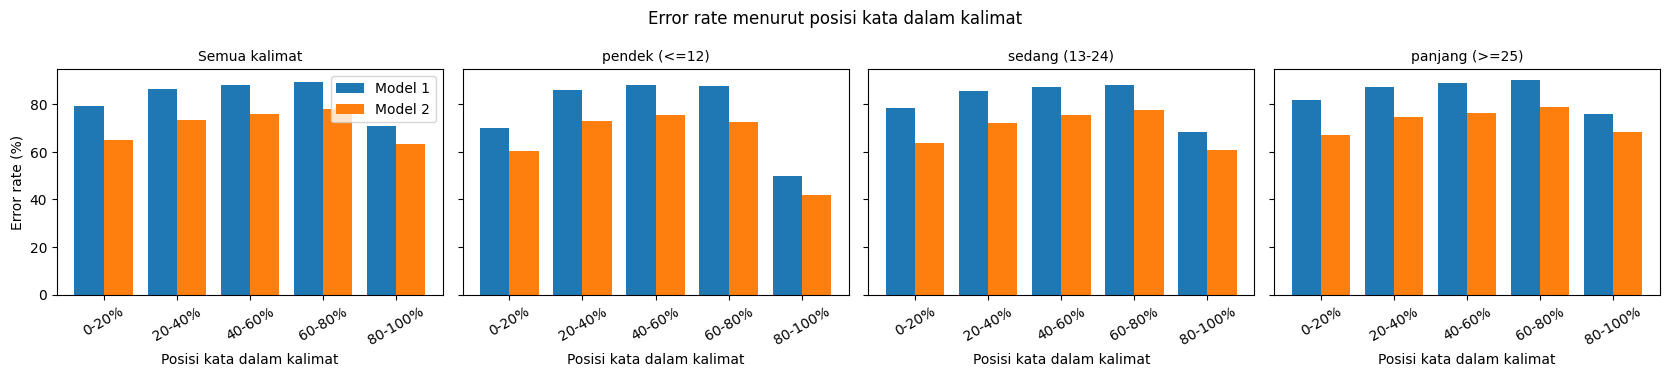

In [ ]:
MAX_LEN = 60

def analyse(hyps, idxs=None):
    idxs = range(len(refs)) if idxs is None else idxs
    ops, missed = collections.Counter(), collections.Counter()
    pos_wrong, pos_total = np.zeros(5), np.zeros(5)
    n_ref = 0
    for k in idxs:
        r, h = refs[k], hyps[k]
        n_ref += len(r)
        wrong = [True] * len(r)
        for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, r, h, autojunk=False).get_opcodes():
            if tag == "equal":
                for i in range(i1, i2):
                    wrong[i] = False
            elif tag == "replace":
                ops["substitusi kata"] += i2 - i1
            elif tag == "delete":
                ops["kata hilang"] += i2 - i1
            elif tag == "insert":
                ops["kata berlebih"] += j2 - j1
            if tag in ("replace", "delete"):
                for i in range(i1, i2):
                    missed[r[i]] += 1
        for i, w in enumerate(wrong):
            b = min(int(5 * i / len(r)), 4)
            pos_total[b] += 1; pos_wrong[b] += w
    return ops, missed, 100 * pos_wrong / np.maximum(pos_total, 1), n_ref

def has_loop(h):
    return any(c >= 3 for c in collections.Counter(zip(h, h[1:])).values())

def symptoms(hyps, idxs):
    toks = [w for k in idxs for w in hyps[k]]
    return {"token <unk> (%)": 100 * sum(w == "<unk>" for w in toks) / max(len(toks), 1),
            "kalimat berulang/loop (%)": 100 * np.mean([has_loop(hyps[k]) for k in idxs]),
            "tidak berhenti (max_len) (%)": 100 * np.mean([len(hyps[k]) >= MAX_LEN for k in idxs]),
            "rasio panjang hasil/ref": len_ratio([refs[k] for k in idxs], [hyps[k] for k in idxs])}

ops1, missed1, pos1, nref_all = analyse(hyps1)
ops2, missed2, pos2, _ = analyse(hyps2)

print("Jenis error, seluruh test (jumlah kata dan per 100 kata referensi)")
tab_ops = pd.DataFrame({"Model 1": ops1, "Model 2": ops2}).fillna(0).astype(int)
tab_ops_100 = (tab_ops / nref_all * 100).round(1).add_suffix(" /100 kata")
display(pd.concat([tab_ops, tab_ops_100], axis=1))
print("\nKata referensi yang paling sering salah - Model 1:", missed1.most_common(10))
print("Kata referensi yang paling sering salah - Model 2:", missed2.most_common(10))

all_idx = list(range(len(refs)))
tab_sym = {}
for nm, h in [("M1", hyps1), ("M2", hyps2)]:
    for g, ids in {"SEMUA": all_idx, **groups_main}.items():
        tab_sym[(g, nm)] = symptoms(h, ids)
tab_sym = pd.DataFrame(tab_sym).T.round(2)
print("\nGejala kegagalan per kelompok panjang:")
display(tab_sym)

# error per jenis per kelompok panjang (per 100 kata referensi)
rows = {}
for b, ids in groups_main.items():
    o1, _, _, n1 = analyse(hyps1, ids); o2, _, _, _ = analyse(hyps2, ids)
    for nm, o in [("M1", o1), ("M2", o2)]:
        rows[(b, nm)] = {k: round(100 * o[k] / n1, 1) for k in ["substitusi kata", "kata hilang", "kata berlebih"]}
tab_ops_bucket = pd.DataFrame(rows).T
print("\nJenis error per kelompok panjang (per 100 kata referensi):")
display(tab_ops_bucket)

labels = ["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"]
x = np.arange(5)
fig, axs = plt.subplots(1, len(groups_main) + 1, figsize=(4.2 * (len(groups_main) + 1), 3.8), sharey=True)
panels = [("Semua kalimat", None)] + [(b, ids) for b, ids in groups_main.items()]
for ax, (ttl, ids) in zip(axs, panels):
    _, _, p1, _ = analyse(hyps1, ids); _, _, p2, _ = analyse(hyps2, ids)
    ax.bar(x - 0.2, p1, 0.4, label="Model 1"); ax.bar(x + 0.2, p2, 0.4, label="Model 2")
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=30); ax.set_title(ttl, fontsize=10)
    ax.set_xlabel("Posisi kata dalam kalimat")
axs[0].set_ylabel("Error rate (%)"); axs[0].legend()
plt.suptitle("Error rate menurut posisi kata dalam kalimat"); plt.tight_layout()
plt.savefig("fig_error_posisi.png", dpi=150); plt.show()

## 15. Ringkasan Hasil dan Kesimpulan
Ringkasan disusun secara otomatis dari hasil training dan evaluasi pada notebook ini. Setiap pernyataan dihasilkan dari tabel dan nilai yang terukur: skor absolut, selisih antar-model, dan pola perubahan terhadap panjang kalimat dinilai secara terpisah. Perbandingan antar-kelompok panjang untuk satu model bersifat deskriptif, sedangkan selisih antar-model diuji dengan paired bootstrap.

In [ ]:
def pts(x):            # BLEU 0-1 -> poin BLEU (0-100)
    return f"{100 * x:.2f}"

def md_table(d, fmt="{:.4f}"):
    cols = [""] + [str(c) if not isinstance(c, tuple) else " ".join(c) for c in d.columns]
    out = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for k, idx in enumerate(d.index):
        name = idx if not isinstance(idx, tuple) else " ".join(idx)
        vals = [d[c].iloc[k] for c in d.columns]
        cells = [str(name)] + [(fmt.format(v) if isinstance(v, (float, np.floating)) else str(v)) for v in vals]
        out.append("| " + " | ".join(cells) + " |")
    return "\n".join(out)

TOL_POIN = 1.0      # selisih (poin BLEU) di bawah ini dianggap relatif sama pada uraian pola
device_name = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"
b4_1, b4_2 = hasil.loc[M1, "BLEU-4"], hasil.loc[M2, "BLEU-4"]
diff = b4_2 - b4_1
ci_txt = f"[{100*ci_lo:+.2f}, {100*ci_hi:+.2f}]"
bs = list(tab_len.index)

L = []
L.append("# Ringkasan Hasil: Machine Translation Indonesia → Inggris (PANL-BPPT)\n")
L.append(f"Data: {len(df)} pasangan kalimat PANL-BPPT (latih {len(train_df)} / validasi {len(val_df)} / uji {len(test_df)}; pembagian berkelompok tanpa kebocoran kalimat), "
         f"vocabulary sumber {len(src_vocab)} dan target {len(trg_vocab)} (MIN_FREQ={MIN_FREQ}). "
         f"Model: encoder GRU dua arah, EMB={EMB}, HID={HID}, ATT={ATT}; {EPOCHS} epoch, learning rate {LR}, batch {BATCH}, teacher forcing {TEACHER_FORCING}, greedy decoding; seed {SEED}. Perangkat training: {device_name}.\n")

# ---- 1. BLEU ----
L.append("## 1. Kualitas Terjemahan dan BLEU\n")
L.append(md_table(hasil) + "\n")
if ci_lo > 0:
    k_bleu = f"Model 2 memperoleh BLEU-4 lebih tinggi pada data uji ({pts(b4_2)} dibanding {pts(b4_1)}; selisih {100*diff:+.2f} poin; interval bootstrap 95% untuk selisih {ci_txt} tidak mencakup nol)."
elif ci_hi < 0:
    k_bleu = f"Model 1 memperoleh BLEU-4 lebih tinggi pada data uji ({pts(b4_1)} dibanding {pts(b4_2)}; selisih Model 2 − Model 1 {100*diff:+.2f} poin; interval bootstrap 95% untuk selisih {ci_txt} tidak mencakup nol)."
else:
    k_bleu = f"Belum terdapat bukti perbedaan BLEU-4 yang jelas pada data uji berdasarkan analisis tersebut (Model 1 {pts(b4_1)}, Model 2 {pts(b4_2)}; interval bootstrap 95% untuk selisih {ci_txt} mencakup nol)."
L.append("- " + k_bleu)
L.append(f"- Proporsi sampel bootstrap (dari 1.000) dengan BLEU-4 Model 2 lebih tinggi daripada Model 1: {100*p_m2_better:.1f}%.")
L.append("- Paired bootstrap mengukur variasi akibat pengambilan sampel data uji dengan model yang sudah dilatih. Bootstrap ini tidak mengukur variasi akibat seed training karena setiap model hanya dilatih satu kali (seed 42). Hasil ini berlaku untuk dataset, konfigurasi, dan seed yang digunakan.\n")

# ---- 2. Kalimat panjang ----
L.append("## 2. Kemampuan Menangani Kalimat Panjang\n")
L.append("BLEU-4 (poin, skala 0–100) per kelompok panjang kalimat sumber:\n")
L.append(md_table(tab_len, fmt="{:.2f}") + "\n")
L.append("BLEU per rentang panjang yang lebih halus (skala 0–1; M1 = Model 1, M2 = Model 2):\n")
L.append(md_table(tab_fine) + "\n")
sup = pd.DataFrame({"rasio panjang keluaran/referensi Model 1": tab_bucket["M1 rasio panjang"], "rasio panjang keluaran/referensi Model 2": tab_bucket["M2 rasio panjang"],
                    "kalimat berulang/loop Model 1 (%)": [tab_sym.loc[(b, "M1"), "kalimat berulang/loop (%)"] for b in bs],
                    "kalimat berulang/loop Model 2 (%)": [tab_sym.loc[(b, "M2"), "kalimat berulang/loop (%)"] for b in bs]}, index=bs)
L.append("Informasi pendukung (rasio panjang dan tingkat pengulangan):\n")
L.append(md_table(sup, fmt="{:.2f}") + "\n")

win = tab_len["Model dengan BLEU-4 lebih tinggi"].tolist()
if all(w == "Model 2" for w in win):
    k_abs = "Berdasarkan skor absolut, Model 2 memperoleh BLEU-4 lebih tinggi pada seluruh kelompok panjang kalimat."
elif all(w == "Model 1" for w in win):
    k_abs = "Berdasarkan skor absolut, Model 1 memperoleh BLEU-4 lebih tinggi pada seluruh kelompok panjang kalimat."
else:
    k_abs = "Berdasarkan skor absolut, model dengan BLEU-4 lebih tinggi berbeda antar-kelompok: " + "; ".join(f"{b}: {w}" for b, w in zip(bs, win)) + "."
L.append("- **Skor absolut.** " + k_abs)
excl = [b for b in bs if tab_len.loc[b, "CI 95% selisih (bawah)"] > 0 or tab_len.loc[b, "CI 95% selisih (atas)"] < 0]
incl = [b for b in bs if b not in excl]
L.append("- **Selisih antar-model.** Selisih absolut (Model 2 − Model 1): " + "; ".join(f"{b}: {tab_len.loc[b, 'Selisih (Model 2 - Model 1)']:+.2f}" for b in bs) + " poin. "
         + (f"Interval bootstrap 95% untuk selisih tidak mencakup nol pada kelompok: {', '.join(excl)}. " if excl else "")
         + (f"Interval mencakup nol pada kelompok: {', '.join(incl)}." if incl else ""))
if len(bs) >= 2:
    first, last = bs[0], bs[-1]
    g_first, g_last = tab_len.loc[first, "Selisih (Model 2 - Model 1)"], tab_len.loc[last, "Selisih (Model 2 - Model 1)"]
    pola_gap = "membesar" if g_last - g_first > TOL_POIN else ("mengecil" if g_first - g_last > TOL_POIN else "relatif sama")
    L.append(f"- **Pola selisih.** Selisih absolut antar-model {pola_gap} dari kelompok {first} ({g_first:+.2f} poin) ke kelompok {last} ({g_last:+.2f} poin) (ambang relatif sama: {TOL_POIN:g} poin).")
    for nm, col in [("Model 1", "BLEU-4 Model 1"), ("Model 2", "BLEU-4 Model 2")]:
        a_, z_ = tab_len.loc[first, col], tab_len.loc[last, col]
        rel = f", atau {100 * (z_ - a_) / a_:+.1f}% secara relatif" if a_ > 0 else ""
        L.append(f"- **Pola perubahan {nm}.** BLEU-4 {nm} berubah dari {a_:.2f} (kelompok {first}) menjadi {z_:.2f} (kelompok {last}), yaitu {z_ - a_:+.2f} poin{rel}.")
L.append("- Perbandingan antar-kelompok untuk satu model bersifat deskriptif: kelompok berisi kalimat yang berbeda dan tidak dilakukan pengujian signifikansi untuk perubahan antar-kelompok. Perubahan relatif tidak menggantikan perbandingan skor absolut, terutama bila skor awal kedua model berbeda jauh.")
L.append("- **Rasio panjang keluaran terhadap referensi.** Rasio di bawah 1 menunjukkan bahwa panjang keluaran model secara rata-rata lebih pendek dibandingkan panjang referensi. Kondisi ini dapat menunjukkan kecenderungan menghasilkan terjemahan yang lebih ringkas, tetapi tidak selalu berarti kalimat terpotong. Rasio di atas 1 menunjukkan keluaran lebih panjang daripada referensi secara rata-rata dan tidak otomatis berarti terjadi penambahan informasi yang salah.\n")

# ---- 3. Waktu dan validation loss ----
L.append("## 3. Waktu Training dan Validation Loss\n")
L.append("Jumlah parameter per komponen:\n")
L.append(md_table(pd.DataFrame(M_COMP).T, fmt="{:,.0f}") + "\n")
tt = tab_train.copy()
tt["Waktu decoding data uji (dtk)"] = [round(dec_time1, 1), round(dec_time2, 1)]
tt["Jumlah parameter"] = [f"{n_params(model1):,}", f"{n_params(model2):,}"]
tt["Epoch dengan val loss terendah"] = tt["Epoch dengan val loss terendah"].astype(int)
L.append(md_table(tt, fmt="{:g}") + "\n")
L.append(f"- Waktu training Model 2 adalah {time2/time1:.2f}× waktu training Model 1 ({time2:.0f} dtk dibanding {time1:.0f} dtk); jumlah parameter Model 2 {n_params(model2):,} dibanding {n_params(model1):,} pada Model 1.")
for nm, h in [("Model 1", hist1), ("Model 2", hist2)]:
    be = int(np.argmin(h["val"])) + 1
    best, last = min(h["val"]), h["val"][-1]
    train_down = h["train"][-1] < h["train"][be - 1]
    if be < EPOCHS and last > best * 1.01:
        s_ = (f"validation loss meningkat setelah epoch terbaik (dari {best:.4f} pada epoch {be} menjadi {last:.4f} pada epoch {EPOCHS})"
              + (" sementara training loss terus turun; ini mengindikasikan memburuknya performa validasi setelah epoch tersebut." if train_down else "."))
    else:
        s_ = f"validation loss tidak meningkat lebih dari 1% setelah epoch terbaik ({best:.4f} pada epoch {be}; {last:.4f} pada epoch {EPOCHS})."
    L.append(f"- {nm}: validation loss terendah pada epoch {be}; {s_}")
L.append(f"- Training memakai teacher forcing {TEACHER_FORCING} sedangkan validasi memakai teacher forcing 0,0, sehingga nilai training loss dan validation loss tidak sebanding secara langsung dan selisih keduanya tidak diinterpretasikan sebagai ukuran overfitting. "
         f"Parameter dengan validation loss terendah (epoch {int(np.argmin(hist1['val'])) + 1} untuk Model 1 dan epoch {int(np.argmin(hist2['val'])) + 1} untuk Model 2) digunakan untuk evaluasi data uji.\n")

# ---- 4. Contoh ----
L.append("## 4. Contoh Prediksi dan Kemiripan Referensi\n")
L.append(f"Kemiripan referensi diukur dengan chrF tingkat kalimat; kategori ditentukan dari kuartil skor kedua model pada data uji (relatif rendah ≤ {q_lo:.3f}, relatif tinggi ≥ {q_hi:.3f}). chrF dan BLEU mengukur kemiripan teks dan bukan kesesuaian makna secara menyeluruh (M1 = Model 1, M2 = Model 2).\n")
L.append(md_table(tab_sim, fmt="{:.3f}") + "\n")
tot = tab_sim.loc["TOTAL"]
L.append(f"- chrF rata-rata pada data uji: Model 1 {tot['M1 chrF rata-rata']:.3f}, Model 2 {tot['M2 chrF rata-rata']:.3f}. Kecocokan persis dengan referensi: Model 1 {int(tot['M1 kecocokan persis'])}, Model 2 {int(tot['M2 kecocokan persis'])} dari {int(tot['n'])} kalimat.")
L.append(f"- Contoh terpilih ({len(tab_contoh)} contoh, lengkap dengan kalimat sumber, referensi, prediksi kedua model, dan skor chrF) disimpan pada `contoh_prediksi_terpilih.csv` dan ditampilkan pada bagian 12.\n")

# ---- 5. Attention ----
L.append("## 5. Visualisasi Attention dan Alignment\n")
L.append(md_table(tab_att) + "\n")
ba = list(tab_att.index[1:])
if len(ba) >= 2:
    ea, ez = tab_att.loc[ba[0], "entropi attention (0-1)"], tab_att.loc[ba[-1], "entropi attention (0-1)"]
    pol = "bobot lebih menyebar" if ez - ea > 0.01 else ("relatif sama" if abs(ez - ea) <= 0.01 else "bobot lebih terkonsentrasi")
    L.append(f"- Entropi Attention (ukuran konsentrasi bobot, bukan ukuran kebenaran alignment) berubah dari {ea:.3f} (kelompok {ba[0]}) menjadi {ez:.3f} (kelompok {ba[-1]}): {pol} pada kalimat yang lebih panjang.")
L.append(f"- Pemeriksaan teknis pada seluruh data uji: penyimpangan maksimum jumlah bobot Attention dari 1 adalah {att_dev_sum:.1e} dan bobot maksimum pada posisi `<pad>` adalah {att_pad_mass:.1e} ("
         + ("normalisasi dan mask padding sesuai)." if (att_dev_sum < 1e-3 and att_pad_mass < 1e-6) else "tidak sesuai harapan)."))
L.append("- Heatmap (bagian 13; berkas `fig_attention_*.png`) menjadi alat interpretasi kualitatif. Pola diagonal tidak otomatis berarti alignment benar dan pola non-diagonal tidak otomatis berarti alignment salah, karena urutan kata Indonesia dan Inggris dapat berbeda.\n")

# ---- 6. Error ----
L.append("## 6. Analisis Error\n")
L.append("Jenis error per 100 kata referensi menurut kelompok panjang:\n")
L.append(md_table(tab_ops_bucket, fmt="{:.1f}") + "\n")
L.append("Gejala kegagalan:\n")
L.append(md_table(tab_sym, fmt="{:.2f}") + "\n")
e1 = [float(v) for v in pos1]; e2 = [float(v) for v in pos2]
L.append(f"- Error rate (%) menurut posisi kata (lima segmen, awal → akhir kalimat): Model 1 {[round(v, 1) for v in e1]}; Model 2 {[round(v, 1) for v in e2]}. "
         f"Selisih segmen akhir dikurangi segmen awal: Model 1 {e1[4]-e1[0]:+.1f} poin persen, Model 2 {e2[4]-e2[0]:+.1f} poin persen.")
L.append(f"- Kata referensi yang paling sering diprediksi salah, Model 1: {missed1.most_common(8)}")
L.append(f"- Kata referensi yang paling sering diprediksi salah, Model 2: {missed2.most_common(8)}\n")

# ---- 7. Kesimpulan ----
L.append("## 7. Kesimpulan\n")
sym1, sym2 = tab_sym.loc[("SEMUA", "M1")], tab_sym.loc[("SEMUA", "M2")]
def banding(a, b, satuan=""):
    return "lebih rendah" if b < a else ("lebih tinggi" if b > a else "sama")
L.append("1. **Kualitas terjemahan dan BLEU.** " + k_bleu)
L.append("2. **Kemampuan menangani kalimat panjang.** " + k_abs + " "
         + ("Selisih absolut antar-model " + pola_gap + f" dari kelompok {bs[0]} ke {bs[-1]}. " if len(bs) >= 2 else "")
         + "Pola perubahan skor masing-masing model terhadap panjang kalimat dilaporkan terpisah pada bagian 2 dan bersifat deskriptif.")
L.append(f"3. **Biaya komputasi.** Model 2 membutuhkan {time2/time1:.2f}× waktu training Model 1 ({time2:.0f} dibanding {time1:.0f} detik) dan memiliki {n_params(model2):,} parameter dibanding {n_params(model1):,} pada Model 1.")
L.append(f"4. **Pola error.** Persentase token `<unk>` pada keluaran Model 2 {banding(sym1['token <unk> (%)'], sym2['token <unk> (%)'])} dibanding Model 1 ({sym2['token <unk> (%)']:.1f}% dibanding {sym1['token <unk> (%)']:.1f}%); "
         f"kalimat berulang/loop pada Model 2 {banding(sym1['kalimat berulang/loop (%)'], sym2['kalimat berulang/loop (%)'])} ({sym2['kalimat berulang/loop (%)']:.1f}% dibanding {sym1['kalimat berulang/loop (%)']:.1f}%); "
         f"substitusi kata per 100 kata referensi pada Model 2 {banding(tab_ops_100.loc['substitusi kata','Model 1 /100 kata'], tab_ops_100.loc['substitusi kata','Model 2 /100 kata'])} ({tab_ops_100.loc['substitusi kata','Model 2 /100 kata']:.1f} dibanding {tab_ops_100.loc['substitusi kata','Model 1 /100 kata']:.1f}).")
L.append("5. **Alignment Attention.** Heatmap pada bagian 13 menjadi dasar interpretasi kualitatif alignment; entropi Attention dan pemeriksaan normalisasi pada bagian 5 hanya melengkapinya dan tidak membuktikan kebenaran alignment.")
if ci_lo > 0:
    general = "Attention memberikan peningkatan BLEU-4 yang didukung interval bootstrap 95%."
elif ci_hi < 0:
    general = "Model tanpa Attention memperoleh BLEU-4 lebih tinggi pada eksperimen ini, dengan interval bootstrap 95% yang tidak mencakup nol."
else:
    general = "Belum terdapat bukti perbedaan BLEU-4 yang jelas karena interval bootstrap 95% mencakup nol."
L.append("6. **Kesimpulan umum.** " + general + " Kesimpulan ini terbatas pada dataset PANL-BPPT, konfigurasi model, dan seed training yang digunakan.\n")

report = "\n".join(L)
try:
    from IPython.display import Markdown, display as _disp
    _disp(Markdown(report))
except ImportError:
    print(report)

# Ringkasan Hasil: Machine Translation Indonesia → Inggris (PANL-BPPT)

Data: 21529 pasangan kalimat PANL-BPPT (latih 17223 / validasi 2152 / uji 2154; pembagian berkelompok tanpa kebocoran kalimat), vocabulary sumber 13036 dan target 13936 (MIN_FREQ=2). Model: encoder GRU dua arah, EMB=64, HID=128, ATT=64; 20 epoch, learning rate 0.002, batch 64, teacher forcing 0.5, greedy decoding; seed 42. Perangkat training: Tesla T4.

## 1. Kualitas Terjemahan dan BLEU

|  | BLEU-1 | BLEU-2 | BLEU-3 | BLEU-4 |
|---|---|---|---|---|
| Model 1 (tanpa attention) | 0.1952 | 0.0630 | 0.0239 | 0.0113 |
| Model 2 (+ attention) | 0.3370 | 0.1710 | 0.0921 | 0.0513 |

- Model 2 memperoleh BLEU-4 lebih tinggi pada data uji (5.13 dibanding 1.13; selisih +4.00 poin; interval bootstrap 95% untuk selisih [+3.69, +4.34] tidak mencakup nol).
- Proporsi sampel bootstrap (dari 1.000) dengan BLEU-4 Model 2 lebih tinggi daripada Model 1: 100.0%.
- Paired bootstrap mengukur variasi akibat pengambilan sampel data uji dengan model yang sudah dilatih. Bootstrap ini tidak mengukur variasi akibat seed training karena setiap model hanya dilatih satu kali (seed 42). Hasil ini berlaku untuk dataset, konfigurasi, dan seed yang digunakan.

## 2. Kemampuan Menangani Kalimat Panjang

BLEU-4 (poin, skala 0–100) per kelompok panjang kalimat sumber:

|  | n kalimat | BLEU-4 Model 1 | BLEU-4 Model 2 | Selisih (Model 2 - Model 1) | Model dengan BLEU-4 lebih tinggi | CI 95% selisih (bawah) | CI 95% selisih (atas) |
|---|---|---|---|---|---|---|---|
| pendek (<=12) | 352 | 0.88 | 5.87 | 4.99 | Model 2 | 3.94 | 6.57 |
| sedang (13-24) | 986 | 1.08 | 5.19 | 4.11 | Model 2 | 3.63 | 4.62 |
| panjang (>=25) | 816 | 1.17 | 4.98 | 3.80 | Model 2 | 3.33 | 4.26 |

BLEU per rentang panjang yang lebih halus (skala 0–1; M1 = Model 1, M2 = Model 2):

|  | n kalimat | M1 BLEU-1 | M1 BLEU-4 | M1 rasio panjang | M2 BLEU-1 | M2 BLEU-4 | M2 rasio panjang |
|---|---|---|---|---|---|---|---|
| 1-12 | 352 | 0.2435 | 0.0088 | 0.9147 | 0.3669 | 0.0587 | 0.9534 |
| 13-18 | 488 | 0.2135 | 0.0124 | 0.9422 | 0.3527 | 0.0561 | 0.9260 |
| 19-24 | 498 | 0.2008 | 0.0096 | 0.9754 | 0.3331 | 0.0489 | 0.9202 |
| 25-30 | 451 | 0.1863 | 0.0128 | 0.9845 | 0.3337 | 0.0517 | 0.9017 |
| 31-40 | 365 | 0.1708 | 0.0105 | 0.9421 | 0.3238 | 0.0477 | 0.9046 |

Informasi pendukung (rasio panjang dan tingkat pengulangan):

|  | rasio panjang keluaran/referensi Model 1 | rasio panjang keluaran/referensi Model 2 | kalimat berulang/loop Model 1 (%) | kalimat berulang/loop Model 2 (%) |
|---|---|---|---|---|
| pendek (<=12) | 0.91 | 0.95 | 42.33 | 21.02 |
| sedang (13-24) | 0.96 | 0.92 | 83.77 | 49.09 |
| panjang (>=25) | 0.96 | 0.90 | 95.71 | 72.92 |

- **Skor absolut.** Berdasarkan skor absolut, Model 2 memperoleh BLEU-4 lebih tinggi pada seluruh kelompok panjang kalimat.
- **Selisih antar-model.** Selisih absolut (Model 2 − Model 1): pendek (<=12): +4.99; sedang (13-24): +4.11; panjang (>=25): +3.80 poin. Interval bootstrap 95% untuk selisih tidak mencakup nol pada kelompok: pendek (<=12), sedang (13-24), panjang (>=25). 
- **Pola selisih.** Selisih absolut antar-model mengecil dari kelompok pendek (<=12) (+4.99 poin) ke kelompok panjang (>=25) (+3.80 poin) (ambang relatif sama: 1 poin).
- **Pola perubahan Model 1.** BLEU-4 Model 1 berubah dari 0.88 (kelompok pendek (<=12)) menjadi 1.17 (kelompok panjang (>=25)), yaitu +0.29 poin, atau +33.4% secara relatif.
- **Pola perubahan Model 2.** BLEU-4 Model 2 berubah dari 5.87 (kelompok pendek (<=12)) menjadi 4.98 (kelompok panjang (>=25)), yaitu -0.89 poin, atau -15.2% secara relatif.
- Perbandingan antar-kelompok untuk satu model bersifat deskriptif: kelompok berisi kalimat yang berbeda dan tidak dilakukan pengujian signifikansi untuk perubahan antar-kelompok. Perubahan relatif tidak menggantikan perbandingan skor absolut, terutama bila skor awal kedua model berbeda jauh.
- **Rasio panjang keluaran terhadap referensi.** Rasio di bawah 1 menunjukkan bahwa panjang keluaran model secara rata-rata lebih pendek dibandingkan panjang referensi. Kondisi ini dapat menunjukkan kecenderungan menghasilkan terjemahan yang lebih ringkas, tetapi tidak selalu berarti kalimat terpotong. Rasio di atas 1 menunjukkan keluaran lebih panjang daripada referensi secara rata-rata dan tidak otomatis berarti terjadi penambahan informasi yang salah.

## 3. Waktu Training dan Validation Loss

Jumlah parameter per komponen:

|  | Encoder | Decoder (tanpa Attention) | Attention | Total |
|---|---|---|---|---|
| Model 1 (tanpa attention) | 1016192 | 2764144 | 0 | 3780336 |
| Model 2 (+ attention) | 1016192 | 7321968 | 24640 | 8362800 |

|  | Jumlah parameter | Waktu training total (dtk) | Rata-rata per epoch (dtk) | Epoch dengan val loss terendah | Val loss terendah | Train loss pada epoch tersebut | Waktu decoding data uji (dtk) |
|---|---|---|---|---|---|---|---|
| Model 1 (tanpa attention) | 3,780,336 | 554.6 | 27.7 | 14 | 6.0502 | 4.8924 | 0.6 |
| Model 2 (+ attention) | 8,362,800 | 846.8 | 42.3 | 5 | 5.2914 | 3.6009 | 1.2 |

- Waktu training Model 2 adalah 1.53× waktu training Model 1 (847 dtk dibanding 555 dtk); jumlah parameter Model 2 8,362,800 dibanding 3,780,336 pada Model 1.
- Model 1: validation loss terendah pada epoch 14; validation loss meningkat setelah epoch terbaik (dari 6.0502 pada epoch 14 menjadi 6.1980 pada epoch 20) sementara training loss terus turun; ini mengindikasikan memburuknya performa validasi setelah epoch tersebut.
- Model 2: validation loss terendah pada epoch 5; validation loss meningkat setelah epoch terbaik (dari 5.2914 pada epoch 5 menjadi 6.3451 pada epoch 20) sementara training loss terus turun; ini mengindikasikan memburuknya performa validasi setelah epoch tersebut.
- Training memakai teacher forcing 0.5 sedangkan validasi memakai teacher forcing 0,0, sehingga nilai training loss dan validation loss tidak sebanding secara langsung dan selisih keduanya tidak diinterpretasikan sebagai ukuran overfitting. Parameter dengan validation loss terendah (epoch 14 untuk Model 1 dan epoch 5 untuk Model 2) digunakan untuk evaluasi data uji.

## 4. Contoh Prediksi dan Kemiripan Referensi

Kemiripan referensi diukur dengan chrF tingkat kalimat; kategori ditentukan dari kuartil skor kedua model pada data uji (relatif rendah ≤ 0.087, relatif tinggi ≥ 0.236). chrF dan BLEU mengukur kemiripan teks dan bukan kesesuaian makna secara menyeluruh (M1 = Model 1, M2 = Model 2).

|  | n | M1 kecocokan persis | M2 kecocokan persis | M1 kemiripan relatif tinggi | M2 kemiripan relatif tinggi | M1 kemiripan relatif rendah | M2 kemiripan relatif rendah | M1 chrF rata-rata | M2 chrF rata-rata |
|---|---|---|---|---|---|---|---|---|---|
| pendek (<=12) | 352 | 0 | 0 | 16 | 154 | 141 | 34 | 0.110 | 0.239 |
| sedang (13-24) | 986 | 0 | 0 | 31 | 450 | 441 | 40 | 0.106 | 0.240 |
| panjang (>=25) | 816 | 0 | 0 | 28 | 398 | 392 | 29 | 0.102 | 0.237 |
| TOTAL | 2154 | 0 | 0 | 75 | 1002 | 974 | 103 | 0.106 | 0.239 |

- chrF rata-rata pada data uji: Model 1 0.106, Model 2 0.239. Kecocokan persis dengan referensi: Model 1 0, Model 2 0 dari 2154 kalimat.
- Contoh terpilih (12 contoh, lengkap dengan kalimat sumber, referensi, prediksi kedua model, dan skor chrF) disimpan pada `contoh_prediksi_terpilih.csv` dan ditampilkan pada bagian 12.

## 5. Visualisasi Attention dan Alignment

|  | entropi attention (0-1) |
|---|---|
| SEMUA | 0.5489 |
| pendek (<=12) | 0.5331 |
| sedang (13-24) | 0.5463 |
| panjang (>=25) | 0.5588 |

- Entropi Attention (ukuran konsentrasi bobot, bukan ukuran kebenaran alignment) berubah dari 0.533 (kelompok pendek (<=12)) menjadi 0.559 (kelompok panjang (>=25)): bobot lebih menyebar pada kalimat yang lebih panjang.
- Pemeriksaan teknis pada seluruh data uji: penyimpangan maksimum jumlah bobot Attention dari 1 adalah 2.4e-07 dan bobot maksimum pada posisi `<pad>` adalah 0.0e+00 (normalisasi dan mask padding sesuai).
- Heatmap (bagian 13; berkas `fig_attention_*.png`) menjadi alat interpretasi kualitatif. Pola diagonal tidak otomatis berarti alignment benar dan pola non-diagonal tidak otomatis berarti alignment salah, karena urutan kata Indonesia dan Inggris dapat berbeda.

## 6. Analisis Error

Jenis error per 100 kata referensi menurut kelompok panjang:

|  | substitusi kata | kata hilang | kata berlebih |
|---|---|---|---|
| pendek (<=12) M1 | 66.8 | 10.0 | 2.9 |
| pendek (<=12) M2 | 54.8 | 10.4 | 5.6 |
| sedang (13-24) M1 | 62.0 | 19.6 | 3.0 |
| sedang (13-24) M2 | 55.7 | 14.1 | 5.7 |
| panjang (>=25) M1 | 58.4 | 26.3 | 2.5 |
| panjang (>=25) M2 | 57.6 | 15.3 | 6.4 |

Gejala kegagalan:

|  | token <unk> (%) | kalimat berulang/loop (%) | tidak berhenti (max_len) (%) | rasio panjang hasil/ref |
|---|---|---|---|---|
| SEMUA M1 | 12.38 | 81.52 | 0.09 | 0.96 |
| pendek (<=12) M1 | 14.45 | 42.33 | 0.00 | 0.91 |
| sedang (13-24) M1 | 12.96 | 83.77 | 0.00 | 0.96 |
| panjang (>=25) M1 | 11.61 | 95.71 | 0.25 | 0.96 |
| SEMUA M2 | 13.29 | 53.53 | 0.37 | 0.92 |
| pendek (<=12) M2 | 9.52 | 21.02 | 0.00 | 0.95 |
| sedang (13-24) M2 | 12.97 | 49.09 | 0.51 | 0.92 |
| panjang (>=25) M2 | 14.15 | 72.92 | 0.37 | 0.90 |

- Error rate (%) menurut posisi kata (lima segmen, awal → akhir kalimat): Model 1 [79.3, 86.2, 87.9, 89.1, 70.8]; Model 2 [65.0, 73.3, 75.9, 77.8, 63.2]. Selisih segmen akhir dikurangi segmen awal: Model 1 -8.5 poin persen, Model 2 -1.8 poin persen.
- Kata referensi yang paling sering diprediksi salah, Model 1: [('in', 983), ('to', 915), ('of', 859), ('a', 841), (',', 695), ('the', 591), ('and', 551), ('on', 433)]
- Kata referensi yang paling sering diprediksi salah, Model 2: [('the', 818), ('to', 765), (',', 751), ('of', 728), ('a', 680), ('in', 650), ('on', 410), ('for', 319)]

## 7. Kesimpulan

1. **Kualitas terjemahan dan BLEU.** Model 2 memperoleh BLEU-4 lebih tinggi pada data uji (5.13 dibanding 1.13; selisih +4.00 poin; interval bootstrap 95% untuk selisih [+3.69, +4.34] tidak mencakup nol).
2. **Kemampuan menangani kalimat panjang.** Berdasarkan skor absolut, Model 2 memperoleh BLEU-4 lebih tinggi pada seluruh kelompok panjang kalimat. Selisih absolut antar-model mengecil dari kelompok pendek (<=12) ke panjang (>=25). Pola perubahan skor masing-masing model terhadap panjang kalimat dilaporkan terpisah pada bagian 2 dan bersifat deskriptif.
3. **Biaya komputasi.** Model 2 membutuhkan 1.53× waktu training Model 1 (847 dibanding 555 detik) dan memiliki 8,362,800 parameter dibanding 3,780,336 pada Model 1.
4. **Pola error.** Persentase token `<unk>` pada keluaran Model 2 lebih tinggi dibanding Model 1 (13.3% dibanding 12.4%); kalimat berulang/loop pada Model 2 lebih rendah (53.5% dibanding 81.5%); substitusi kata per 100 kata referensi pada Model 2 lebih rendah (56.6 dibanding 60.5).
5. **Alignment Attention.** Heatmap pada bagian 13 menjadi dasar interpretasi kualitatif alignment; entropi Attention dan pemeriksaan normalisasi pada bagian 5 hanya melengkapinya dan tidak membuktikan kebenaran alignment.
6. **Kesimpulan umum.** Attention memberikan peningkatan BLEU-4 yang didukung interval bootstrap 95%. Kesimpulan ini terbatas pada dataset PANL-BPPT, konfigurasi model, dan seed training yang digunakan.


## 16. Keterbatasan Eksperimen

In [ ]:
LIMITS = [
    "Setiap model dilatih satu kali dengan seed 42; hasil dapat berbeda pada seed lain.",
    "Paired bootstrap hanya mengukur variasi akibat pengambilan sampel data uji dengan model yang sudah dilatih, bukan variasi akibat seed training.",
    "BLEU bergantung pada kecocokan n-gram terhadap satu referensi sehingga terjemahan yang benar tetapi berbeda pilihan kata dapat memperoleh skor rendah; chrF juga hanya mengukur kemiripan teks.",
    "Tokenisasi berbasis kata menyebabkan kata langka, nama diri, dan angka menjadi `<unk>` (out-of-vocabulary), sehingga tidak dapat diterjemahkan secara eksplisit.",
    "Greedy decoding dapat menghasilkan keluaran yang monoton atau berulang karena hanya memilih kata berprobabilitas tertinggi pada setiap langkah.",
    "Dataset PANL-BPPT memiliki keterbatasan kualitas pasangan (sebagian terjemahan longgar, tidak sejajar, atau mengandung artefak encoding dan typo) dan keterbatasan cakupan domain (berita ekonomi, internasional, sains/teknologi, dan olahraga).",
    "Filter rasio panjang merupakan heuristik dan bukan jaminan kesepadanan makna pasangan yang tersisa.",
    "Heatmap Attention tidak menjamin interpretasi kausal maupun kebenaran terjemahan.",
]
limit_md = "\n".join(f"{k}. {t}" for k, t in enumerate(LIMITS, 1))
try:
    from IPython.display import Markdown, display as _disp
    _disp(Markdown(limit_md))
except ImportError:
    print(limit_md)

# ---- penyimpanan hasil ----
with open("ringkasan_hasil.md", "w", encoding="utf-8") as f:
    f.write(report + "\n\n## 8. Keterbatasan Eksperimen\n\n" + limit_md + "\n")
pd.concat({"keseluruhan": hasil, "kelompok_panjang": tab_bucket, "rentang_halus": tab_fine, "bleu4_kelompok_dan_bootstrap": tab_len}, axis=0).to_csv("hasil_bleu.csv")
with open("hasil.json", "w", encoding="utf-8") as f:
    json.dump({"bleu": hasil.round(6).to_dict(orient="index"),
               "bleu4_selisih_model2_minus_model1": float(diff), "bootstrap_ci95_selisih": [float(ci_lo), float(ci_hi)],
               "bleu4_per_kelompok": {b: {k: (float(v) if not isinstance(v, str) else v) for k, v in tab_len.loc[b].items()} for b in tab_len.index},
               "waktu_training_detik": {"model1": time1, "model2": time2},
               "parameter": {"model1": n_params(model1), "model2": n_params(model2)},
               "epoch_terbaik": {"model1": int(np.argmin(hist1["val"])) + 1, "model2": int(np.argmin(hist2["val"])) + 1},
               "jumlah_kalimat": {"latih": len(train_df), "validasi": len(val_df), "uji": len(test_df)}},
              f, indent=2, ensure_ascii=False)
print("Berkas hasil tersimpan: ringkasan_hasil.md, hasil_bleu.csv, hasil.json, contoh_prediksi_terpilih.csv, audit_dibuang_rasio.csv, fig_*.png, model1_noattn.pt, model2_attn.pt")

1. Setiap model dilatih satu kali dengan seed 42; hasil dapat berbeda pada seed lain.
2. Paired bootstrap hanya mengukur variasi akibat pengambilan sampel data uji dengan model yang sudah dilatih, bukan variasi akibat seed training.
3. BLEU bergantung pada kecocokan n-gram terhadap satu referensi sehingga terjemahan yang benar tetapi berbeda pilihan kata dapat memperoleh skor rendah; chrF juga hanya mengukur kemiripan teks.
4. Tokenisasi berbasis kata menyebabkan kata langka, nama diri, dan angka menjadi `<unk>` (out-of-vocabulary), sehingga tidak dapat diterjemahkan secara eksplisit.
5. Greedy decoding dapat menghasilkan keluaran yang monoton atau berulang karena hanya memilih kata berprobabilitas tertinggi pada setiap langkah.
6. Dataset PANL-BPPT memiliki keterbatasan kualitas pasangan (sebagian terjemahan longgar, tidak sejajar, atau mengandung artefak encoding dan typo) dan keterbatasan cakupan domain (berita ekonomi, internasional, sains/teknologi, dan olahraga).
7. Filter rasio panjang merupakan heuristik dan bukan jaminan kesepadanan makna pasangan yang tersisa.
8. Heatmap Attention tidak menjamin interpretasi kausal maupun kebenaran terjemahan.

Berkas hasil tersimpan: ringkasan_hasil.md, hasil_bleu.csv, hasil.json, contoh_prediksi_terpilih.csv, audit_dibuang_rasio.csv, fig_*.png, model1_noattn.pt, model2_attn.pt
